# HS trial simulation: a generative model split from the predictive one

**Purpose.** Choose sample size, endpoint, visit schedule and enrichment *before* a hidden-suppurativa-type trial, using what the real-world data say about disease activity, scoring noise, treatment response and drop-out.

A trial simulator answer *"what data would a trial produce under assumption X?"*, so it needs a **mechanism** that can be changed one assumption at a time:

| block | what it generates | estimated from |
|---|---|---|
| 1 baseline patients | Hurley stage, mean activity level | first-line biologic starters (the closest thing to a trial population) |
| 2 latent activity | stable level + flares that arrive at random and decay | antibiotic courses (flare markers) and the scores around them |
| 3 visits and scoring | which visits happen, which are scored, by site | visit table, practitioner variation |
| 4 measurement noise | score = activity + noise (integer, noise grows with level) | same-day / close score pairs |
| 5 treatment curve | response in months 1-4, plateau, slow drift, return after stopping, response types as a mixture | first-line biologic starts and stops |
| 6 discontinuation and placebo | stopping hazard by type; placebo response | stopping: data. **Placebo: NOT estimable here (no placebo group): it is a scenario parameter with a range.** |
| 7 simulator | xxxx | the model |
| 8 sensitivity analysis | xxxx | xxxx |
| 9 ledger and limits | checking limits | abglation gate |


**Evidence labels** follow the forecast notebook: CLINICAL (real pattern), ARTEFACT (comes from how data were recorded) or UNDETERMINED (with the evidence that would settle it).

**Checks built in:** (V1) recover known parameters from simulated data; (V2) simulated *untreated* data against real held-out patients; (V3) simulated *biologic starters* against real held-out patients (change distribution, variance, drop-out); then a sensitivity analysis on every assumption, reporting **ranges, not single answers**.

# 0 - packages

In [58]:
import os, warnings, time, json, urllib.request, copy
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats, optimize
from sklearn.mixture import GaussianMixture
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 100

# 1 - baseline patients

In [19]:
# function helper -- general

def _src(d, name):
    d = str(d).rstrip("/")
    if d.startswith("http"): d = d.replace("https://github.com/", "https://raw.githubusercontent.com/").replace("/blob/", "/").replace("/tree/", "/")
    return f"{d}/{name}"

# step checker
LEDGER = []
def check(step, name, ok, detail="", warn=False):
    status = "PASS" if ok else ("WARN" if warn else "FAIL"); LEDGER.append(dict(step=step, check=name, status=status, detail=str(detail))); print(status, "|", step, "|", name, "|", detail)

In [20]:
# function helper -- analysis

# flag on going biologics
def onbio_flag(visits, trt_):
    # True when the visit falls inside a biologic line of that patient (open line = still running)
    b = trt_[trt_.treatment_class == "Biologic"].groupby("patient_id"); flag = np.zeros(len(visits), bool); v = visits.reset_index(drop=True)
    for p, g in v.groupby("patient_id"):
        if p in b.groups:
            for s, e in zip(*[b.get_group(p)[c] for c in ("start_date", "end_date")]):
                flag[g.index[(g.visit_date >= s) & ((g.visit_date < e) | pd.isna(e))]] = True
    return flag

# flag activity related to antibiotic consumption
def rel_to_antibiotic(visits, trt_):
    # signed days from the nearest antibiotic course start (visit - start); +inf if the patient has none
    ab = trt_[trt_.treatment_class == "Antibiotic"].groupby("patient_id").start_date.apply(lambda x: np.sort(x.values)).to_dict(); v = visits.reset_index(drop=True); out = np.full(len(v), np.inf)
    for p, g in v.groupby("patient_id"):
        a = ab.get(p)
        if a is None: continue
        t = g.visit_date.values; j = np.searchsorted(a, t); prev = np.where(j > 0, (t - a[np.maximum(j - 1, 0)]) / np.timedelta64(1, "D"), np.inf); nxt = np.where(j < len(a), (a[np.minimum(j, len(a) - 1)] - t) / np.timedelta64(1, "D"), np.inf)
        out[g.index.values] = np.where(prev <= nxt, prev, -nxt)
    return out

# shrinking
def eb_level(m, n, v, g):
    # empirical-Bayes shrink of patient means toward their group mean (noise-aware), same idea as the forecast notebook
    out = pd.Series(np.nan, index=m.index)
    for h in g.dropna().unique():
        i = g == h; mu = m[i].mean(); s2w = np.nanmean(v[i][n[i] >= 2]); s2b = max(m[i].var() - np.nanmean(s2w / n[i]), 1e-3); k = s2w / s2b; out[i] = (n[i] * m[i] + k * mu) / (n[i] + k)
    return out

In [21]:
# train data set input

DATA_DIR = "https://github.com/FairzanIsLearning/Chemometric-learn/blob/main/Mixed/HS_Model/Raw_data"        # folder with the TRAIN csv files
END = pd.Timestamp("2025-12-31")                       # 

dem = pd.read_csv(_src(DATA_DIR, "demographics.csv"), parse_dates=["symptom_onset_date", "diagnosis_date"])
asg = pd.read_csv(_src(DATA_DIR, "patient_assignment.csv"))
trt = pd.read_csv(_src(DATA_DIR, "treatments.csv"), parse_dates=["start_date", "end_date"])
vis_parts = [
    pd.read_csv(_src(DATA_DIR, name), parse_dates=["visit_date"])
    for name in ("visits1.csv", "visits2.csv")
]
vis = (
    pd.concat(vis_parts, ignore_index=True)
      .drop_duplicates()                                   # safe guard if the split files overlap
      .sort_values(["patient_id", "visit_date"])
      .reset_index(drop=True)
)
print(f"visits1: {len(vis_parts[0]):,} rows | visits2: {len(vis_parts[1]):,} rows | merged: {len(vis):,} rows")

visits1: 425,363 rows | visits2: 284,327 rows | merged: 709,690 rows


In [22]:
# divide by hurley stage baseline
HUR = dem.set_index("patient_id").hurley_stage_baseline
rs = np.random.default_rng(2026); pid = dem.patient_id.values; half = pd.Series(rs.random(len(pid)) < 0.5, index=pid)   # split-sample: calibrate on A, test on B

print(f"{len(dem)} patients | {len(vis)} visits ({vis.
      ihs4_score.notna().mean():.0%} scored) | {(trt.treatment_class=='Biologic').sum()} biologic lines | {(trt.treatment_class=='Antibiotic').sum()} antibiotic courses")
print("scores are integers:", bool((vis.ihs4_score.dropna() % 1 == 0).all()), "| range", vis.ihs4_score.min(), "-", vis.ihs4_score.max())

check("T0 data", "there is NO untreated randomised arm in the data (placebo response cannot be estimated)", True, "placebo is a scenario parameter with a range")

21000 patients | 709690 visits (64% scored) | 16447 biologic lines | 187365 antibiotic courses
scores are integers: True | range 0.0 - 45.0
PASS | T0 data | there is NO untreated randomised arm in the data (placebo response cannot be estimated) | placebo is a scenario parameter with a range


In [23]:
# analyze the biologics and antibiotic use
sc_all = vis[vis.ihs4_score.notna()][["patient_id", "visit_date", "visit_type", "ihs4_score"]].reset_index(drop=True)
sc_all["onb"] = onbio_flag(sc_all, trt); sc_all["rel"] = rel_to_antibiotic(sc_all, trt); sc_all["H"] = sc_all.patient_id.map(HUR)

print("scored visits on a biologic:", f"{sc_all.onb.mean():.0%}", "| within 14 days after an antibiotic start:", f"{((sc_all.rel>=0)&(sc_all.rel<14)).mean():.0%}")

scored visits on a biologic: 47% | within 14 days after an antibiotic start: 27%


# 2 - latent activity

In [24]:
# function helper -- analysis

# estimating noise
def est_noise(sc):
    g = sc.groupby("patient_id"); 
    d = sc.assign(prev_d=g.visit_date.diff().dt.days, prev_s=g.ihs4_score.shift(), prev_t=g.visit_type.shift()).dropna(subset=["prev_d"])
    d["half_sq"] = 0.5 * (d.ihs4_score - d.prev_s) ** 2; d["m"] = (d.ihs4_score + d.prev_s) / 2
    same = d[d.prev_d == 0]
    # linear noise variance in the level: var = n0 + n1 * m   (weighted least squares on same-day pairs)
    X_ = np.c_[np.ones(len(same)), same.m.values]; coef = np.linalg.lstsq(X_, same.half_sq.values, rcond=None)[0]
    # semivariogram of non-flare pairs at lags 1..14 d, extrapolated to lag 0 as a check
    nf = d[(d.prev_d >= 1) & (d.prev_d <= 14) & (d.visit_type != "flare_reactive") & (d.prev_t != "flare_reactive")]; sl = np.polyfit(nf.prev_d, nf.half_sq, 1)
    return dict(n0=float(coef[0]), n1=float(coef[1]), nugget_same_day=float(same.half_sq.mean()), nugget_extrapolated=float(sl[1]), n_pairs_same_day=int(len(same))), d

{'n0': 2.017, 'n1': 0.004, 'nugget_same_day': 2.082, 'nugget_extrapolated': 2.23, 'n_pairs_same_day': 2193}
PASS | T2 noise | same-day nugget and the extrapolated 1-14 day nugget agree within 1 point of variance | 2.08 vs 2.23
PASS | T2 noise | noise variance grows with the level (n1 > 0) | n0 = 2.02, n1 = 0.004


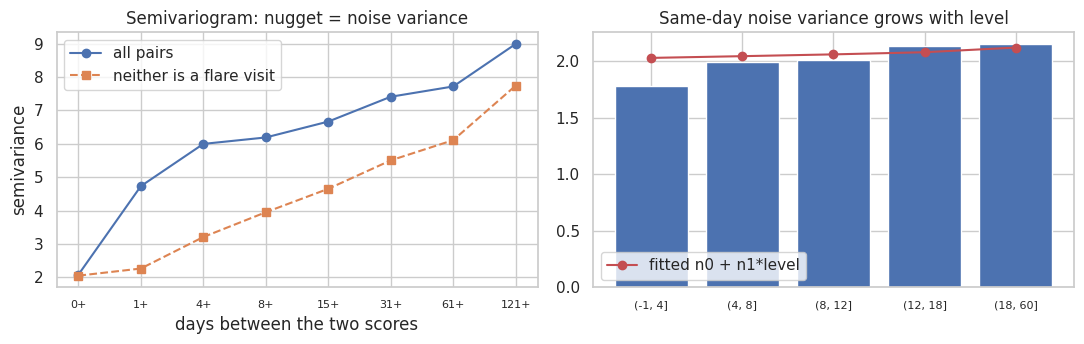

In [25]:
# estimating noise
NOISE, pairs = est_noise(sc_all[sc_all.patient_id.map(half)])
print({k: round(v, 3) for k, v in NOISE.items()})
lagbins = [0, 1, 4, 8, 15, 31, 61, 121, 366]; q = pairs.assign(lag=pd.cut(pairs.prev_d, lagbins, right=False)); sv = q.groupby("lag").half_sq.agg(["mean", "size"]); svn = q[(q.visit_type != "flare_reactive") & (q.prev_t != "flare_reactive")].groupby("lag").half_sq.mean()

# graph
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6)); 
ax[0].plot(range(len(sv)), sv["mean"].values, "o-", label="all pairs"); 
ax[0].plot(range(len(svn)), svn.values, "s--", label="neither is a flare visit"); 
ax[0].set_xticks(range(len(sv))); 
ax[0].set_xticklabels([f"{a}+" for a in lagbins[:-1]], fontsize=8); 
ax[0].set_xlabel("days between the two scores"); 
ax[0].set_ylabel("semivariance"); 
ax[0].legend(); ax[0].set_title("Semivariogram: nugget = noise variance")

s0 = pairs[pairs.prev_d == 0]; b = s0.groupby(pd.cut(s0.m, [-1, 4, 8, 12, 18, 60])).half_sq.agg(["mean", "size"]); 
ax[1].bar(range(len(b)), b["mean"].values); 
ax[1].plot(range(len(b)), NOISE["n0"] + NOISE["n1"] * s0.groupby(pd.cut(s0.m, [-1, 4, 8, 12, 18, 60])).m.mean().values, "r-o", label="fitted n0 + n1*level"); 
ax[1].set_xticks(range(len(b))); ax[1].set_xticklabels([str(i) for i in b.index], fontsize=8); 
ax[1].set_title("Same-day noise variance grows with level"); 
ax[1].legend(); plt.tight_layout()

check("T2 noise", "same-day nugget and the extrapolated 1-14 day nugget agree within 1 point of variance", abs(NOISE["nugget_same_day"] - NOISE["nugget_extrapolated"]) < 1.0, f"{NOISE['nugget_same_day']:.2f} vs {NOISE['nugget_extrapolated']:.2f}")
check("T2 noise", "noise variance grows with the level (n1 > 0)", NOISE["n1"] > 0, f"n0 = {NOISE['n0']:.2f}, n1 = {NOISE['n1']:.3f}")

# 3 - visits and scoring

In [42]:
# function helper -- analysis

# defining exposure
def exposure_table(dem_, trt_):
    first_day = dem_.set_index("patient_id").diagnosis_date.clip(lower=pd.Timestamp("2016-01-02"))
    days_observed = (END - first_day).dt.days.clip(lower=0)

    # Days on a biologic
    bio = trt_[trt_.treatment_class == "Biologic"]
    bio_days = (bio.end_date.fillna(END) - bio.start_date).dt.days.clip(lower=0)
    days_on = (bio_days.groupby(bio.patient_id).sum()
                       .reindex(days_observed.index)   # patients who never had a biologic -> NaN
                       .fillna(0))   

    days_off = (days_observed - days_on).clip(lower=0)

    return pd.DataFrame({"off_y": days_off / 365.25,
                         "on_y":  days_on  / 365.25}, index=days_observed.index)

# estimating flares
def est_flare(sc, trt_, dem_, hur):
    sc = sc.copy()
    exposure = exposure_table(dem_, trt_)

    # Antibiotic course starts, flagged whether the patient was on a biologic at the time
    antibiotics = trt_[trt_.treatment_class == "Antibiotic"][["patient_id", "start_date"]]
    antibiotics["onb"] = onbio_flag(antibiotics.rename(columns={"start_date": "visit_date"}), trt_)

    # Number of courses per patient while OFF biologic (0 if none)
    courses_off = (antibiotics[~antibiotics.onb].groupby("patient_id").size()
                   .reindex(exposure.index).fillna(0))

    hurley = hur.reindex(exposure.index)
    lam = {int(h): float(courses_off[hurley == h].sum() / exposure.off_y[hurley == h].sum())
           for h in (1, 2, 3)}                      # courses per patient-year, by Hurley stage

    # each patient's quiet level and the excess around a flare
    off = sc[~sc.onb].copy() # scores while off biologic only

    # Quiet level = median score taken more than 120 days away from any antibiotic course
    # (needs at least 3 such scores)
    quiet = off[off.rel.abs() > 120].groupby("patient_id").ihs4_score.agg(["median", "size"])
    quiet = quiet[quiet["size"] >= 3]

    off = off.join(quiet["median"].rename("quiet_level"), on="patient_id").dropna(subset=["quiet_level"])
    off["excess"] = off.ihs4_score - off.quiet_level  # how far above normal this score is

    # Keep scores from 0 to 90 days AFTER a course started
    after = off[(off.rel >= 0) & (off.rel < 90)]

    # average excess by week since course start, then fit a decay curve 
    week_edges = np.arange(0, 91, 7)
    week_mid = (week_edges[:-1] + week_edges[1:]) / 2
    by_week = after.groupby(pd.cut(after.rel, week_edges, right=False), observed=False).excess.agg(["mean", "size", "var"])

    def decay(days, amplitude, tau):
        return amplitude * np.exp(-days / tau)

    (amp, tau), _ = optimize.curve_fit(
        decay, week_mid, by_week["mean"].values,
        p0=[4, 15],                                   # starting guess: amplitude 4, tau 15 days
        sigma=1 / np.sqrt(by_week["size"].values),    # weeks with more scores count more
        bounds=([0.1, 2], [30, 80]))                  # keep values plausible

    # how flare size differs between Hurley stages 
    first_2_weeks = after[after.rel < 14].groupby("H").excess.mean()
    amp_scale = (first_2_weeks / first_2_weeks.mean()).to_dict()   # relative to the average stage

    # how variable the flare amplitude is (gamma shape) 
    # Variance of excess just after onset = true flare variability + measurement noise (+30% margin)
    first_days = after[after.rel < 4]
    noise_var = (NOISE["n0"] + NOISE["n1"] * first_days.ihs4_score.mean()) * 1.3
    flare_var = max(first_days.excess.var() - noise_var, 0.3)
    amp_shape = float(np.clip(amp ** 2 / flare_var, 1.0, 8.0))

    params = dict(lam=lam, amp=float(amp), tau=float(tau),
                  amp_scale={int(k): float(v) for k, v in amp_scale.items()},
                  amp_shape=amp_shape)
    return params, by_week, week_mid

# estimating visits
def est_visits(vis_, trt_, dem_, asg_, hur):
    v = vis_.copy()
    v["onb"] = onbio_flag(v, trt_) # visit happened while on a biologic
    v["H"] = v.patient_id.map(hur) # Hurley stage of the patient

    exposure = exposure_table(dem_, trt_).join(hur.rename("H"))

    # how often is a score recorded, by visit type?
    share_by_type = v.visit_type.value_counts(normalize=True)
    p_score = v.groupby("visit_type").ihs4_score.agg(lambda s: s.notna().mean())

    # routine (non-reactive) visits 
    routine = v[v.visit_type != "flare_reactive"]
    share_nonreactive = routine.visit_type.value_counts(normalize=True)

    # Visits per patient-year, by (Hurley stage, on biologic 0/1)
    visit_rate = {}
    for (h, on_bio), group in routine.groupby(["H", "onb"]):
        years = (exposure.on_y if on_bio else exposure.off_y)[exposure.H == h].sum()
        visit_rate[(int(h), int(on_bio))] = float(len(group) / max(years, 1e-6))

    #  does a flare (antibiotic course) bring a reactive visit within +/- 7 days? 
    antibiotics = trt_[trt_.treatment_class == "Antibiotic"][["patient_id", "start_date"]]
    reactive_dates = (v[v.visit_type == "flare_reactive"]
                      .groupby("patient_id").visit_date
                      .apply(lambda x: np.sort(x.values)).to_dict())   # sorted dates per patient

    n_courses = n_with_reactive_visit = 0
    week = np.timedelta64(7, "D")
    for patient, group in antibiotics.groupby("patient_id"):
        dates = reactive_dates.get(patient)
        for start in group.start_date.values:
            n_courses += 1
            if dates is not None:
                first_in_window = np.searchsorted(dates, start - week)   # first reactive visit >= start-7d
                if first_in_window < len(dates) and dates[first_in_window] <= start + week:
                    n_with_reactive_visit += 1
    p_react = n_with_reactive_visit / max(n_courses, 1)

    # do practitioners differ in how often they score, beyond chance? 
    with_prac = v.merge(asg_, on="patient_id", how="left", suffixes=("", "_a"))
    per_prac = with_prac.groupby("practitioner_id").ihs4_score.agg(n="size", k=lambda s: s.notna().sum())
    per_prac = per_prac[per_prac.n >= 50]  # ignore practitioners with few visits

    overall = per_prac.k.sum() / per_prac.n.sum() # overall probability of scoring
    observed_var = (per_prac.k / per_prac.n).var() # spread between practitioners
    chance_var = (overall * (1 - overall) / per_prac.n).mean() # spread expected from luck alone
    practitioner_sd = float(np.sqrt(max(observed_var - chance_var, 0)))

    return dict(p_score=p_score.to_dict(),
                share_nonreactive=share_nonreactive.to_dict(),
                visit_rate=visit_rate,
                p_react=p_react,
                practitioner_sd_prob=practitioner_sd,
                reactive_share=float(share_by_type.get("flare_reactive", 0)))

{'lam': {1: 1.29, 2: 2.39, 3: 2.52}, 'amp': 4.91, 'tau': 15.4, 'amp_scale': {1: 0.61, 2: 0.85, 3: 1.54}, 'amp_shape': 1.34}
PASS | T3 flares | flare excess is positive at onset and gone by ~2 months (jump + decay, not a step) | first week 3.89, last weeks -0.14
PASS | T3 flares | decay time constant is between 5 and 40 days | tau = 15.4 d


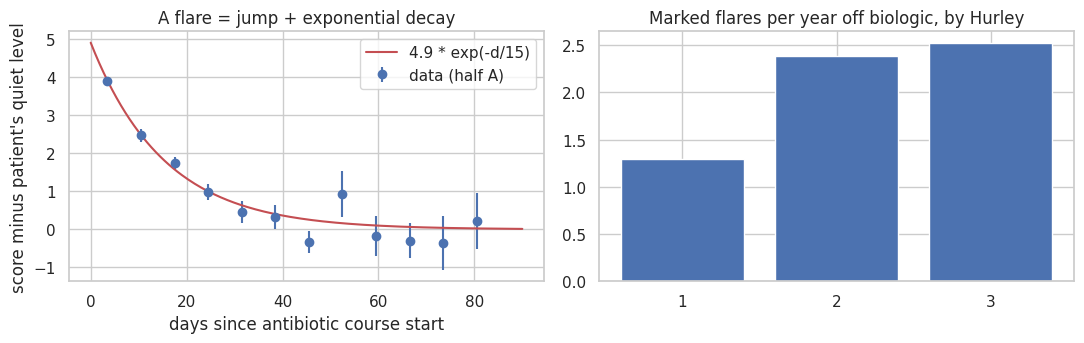

In [27]:
# analysing flares
FLARE, cur_ex, mid = est_flare(sc_all[sc_all.patient_id.map(half)], trt, dem, HUR)
print({k: (round(v, 2) if not isinstance(v, dict) else {a: round(b, 2) for a, b in v.items()}) for k, v in FLARE.items()})

# graph
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6)); 
ax[0].errorbar(mid, cur_ex["mean"], yerr=1.96 * np.sqrt(cur_ex["var"] / cur_ex["size"]), fmt="o", label="data (half A)"); xx = np.linspace(0, 90, 200); ax[0].plot(xx, FLARE["amp"] * np.exp(-xx / FLARE["tau"]), "r-", label=f"{FLARE['amp']:.1f} * exp(-d/{FLARE['tau']:.0f})"); 
ax[0].set_xlabel("days since antibiotic course start"); 
ax[0].set_ylabel("score minus patient's quiet level"); 
ax[0].legend(); 
ax[0].set_title("A flare = jump + exponential decay")

ax[1].bar([str(k) for k in FLARE["lam"]], list(FLARE["lam"].values())); 
ax[1].set_title("Marked flares per year off biologic, by Hurley"); plt.tight_layout()

# checking
check("T3 flares", "flare excess is positive at onset and gone by ~2 months (jump + decay, not a step)", cur_ex["mean"].iloc[0] > 1.5 and abs(cur_ex["mean"].iloc[-3:].mean()) < 0.6, f"first week {cur_ex['mean'].iloc[0]:.2f}, last weeks {cur_ex['mean'].iloc[-3:].mean():.2f}")
check("T3 flares", "decay time constant is between 5 and 40 days", 5 < FLARE["tau"] < 40, f"tau = {FLARE['tau']:.1f} d")

In [28]:
# analysing visits

VIS = est_visits(vis[vis.patient_id.map(half)], trt, dem, asg, HUR)

print("scored share by visit type:", {k: round(v, 2) for k, v in VIS["p_score"].items()}); print("non-reactive visits per year (Hurley, on biologic):", {k: round(v, 1) for k, v in VIS["visit_rate"].items()})
print(f"flares with a reactive visit within 7 d: {VIS['p_react']:.2f} | site-to-site SD of scoring probability: {VIS['practitioner_sd_prob']:.3f}")

check("T3 visits", "sites differ in how often they score beyond chance (informative documentation)", VIS["practitioner_sd_prob"] > 0.05, f"SD {VIS['practitioner_sd_prob']:.3f}")

scored share by visit type: {'background': 0.59, 'flare_reactive': 0.67, 'follow_up': 0.68, 'treatment_monitoring': 0.56}
non-reactive visits per year (Hurley, on biologic): {(1, 0): 1.3, (2, 0): 2.7, (2, 1): 3.7, (3, 0): 2.9, (3, 1): 3.8}
flares with a reactive visit within 7 d: 0.34 | site-to-site SD of scoring probability: 0.175
PASS | T3 visits | sites differ in how often they score beyond chance (informative documentation) | SD 0.175


# 4 - measurement noise

In [29]:
# function helper -- general

def logistic(x, midpoint, width):
    """S-shaped curve from 0 to 1. Equals 0.5 at x = midpoint; a smaller width means a sharper rise."""
    return 1 / (1 + np.exp(-(x - midpoint) / width))

def curve_value(m, c):
    """Fitted score/pre-drug ratio at month m since start, for one response type's parameters c."""
    ramp  = 1 - (1 - c["rho"]) * logistic(m + 0.5, c["t50"], c["w"])
    drift = c["drift_per_year"] * np.maximum(m - 6, 0) / 12
    return ramp + drift

In [30]:
# function helper -- analysis

# estimating treatment received
def est_treatment(vis_, trt_, dem_, hur, seed=0):
    TYPES = np.array(["deep", "partial", "minimal"]) # ordered from best to worst responder
    MONTH = 30.4 # days per month

    bio   = trt_[trt_.treatment_class == "Biologic"]
    line1 = bio[bio.treatment_line == 1].set_index("patient_id")  # first biologic per patient

    # Step 1: scores with "days since first biologic started" 
    scores = (vis_[vis_.ihs4_score.notna()][["patient_id", "visit_date", "visit_type", "ihs4_score"]]
              .join(line1.start_date.rename("t0"), on="patient_id", how="inner"))
    scores["d"] = (scores.visit_date - scores.t0).dt.days

    # Step 2: pre-drug level vs on-drug level, per patient
    def level(mask):  # mean, count, variance of scores per patient
        return scores[mask].groupby("patient_id").ihs4_score.agg(["mean", "size", "var"])

    pre = level((scores.d < 0)   & (scores.d >= -365)) # the year before the start
    on  = level((scores.d >= 90) & (scores.d <= 730)) # months 3 to 24 on drug

    r = pre.join(on, lsuffix="_p", rsuffix="_o", how="inner") # patients with both
    r["H"] = hur.reindex(r.index)
    r = r[r.H.isin([2, 3])].copy() # Hurley 1 never gets a biologic anyway

    # Shrink noisy patient means toward their Hurley-stage mean (avoids fake extreme responders)
    r["pre_s"] = eb_level(r.mean_p, r.size_p, r.var_p, r.H)
    r["on_s"]  = eb_level(r.mean_o, r.size_o, r.var_o, r.H)

    # log(on / pre): negative = improved. This is the number that defines "response".
    r["lr"] = np.log(np.clip(r.on_s, 0.3, None) / r.pre_s)
    r = r.replace([np.inf, -np.inf], np.nan).dropna(subset=["lr"])

    # Step 3: split patients into 3 response types 
    gm = GaussianMixture(3, random_state=seed, n_init=5).fit(r[["lr"]])
    order = np.argsort(gm.means_.ravel())# most negative mean first = deep responders
    prob = gm.predict_proba(r[["lr"]])[:, order]
    r["type"] = TYPES[prob.argmax(1)]
    mix = dict(w=gm.weights_[order], # share of each type
               mu=gm.means_.ravel()[order], # mean log-ratio of each type
               sd=np.sqrt(gm.covariances_.ravel()[order]))

    # Step 4: time course of the response, by type 
    scores_t = scores.join(r[["pre_s", "type"]], on="patient_id", how="inner")
    scores_t["month"] = np.floor(scores_t.d / MONTH).astype(int)
    scores_t["ratio"] = scores_t.ihs4_score / scores_t.pre_s          # 1 = same as before the drug
    tc = (scores_t[(scores_t.month >= -3) & (scores_t.month <= 30)]
          .groupby(["type", "month"]).ratio.agg(["mean", "size"]).reset_index()
          .rename(columns={"month": "m"}))

    curves = {}
    for t in TYPES:
        this = tc[tc.type == t]
        ramp    = this[this.m.between(0, 12)] # the months where the response builds up
        plateau = this[this.m.between(5, 12)] # where it has levelled off
        late    = this[this.m.between(6, 30)] # where we look for slow drift

        rho = float(np.average(plateau["mean"], weights=plateau["size"])) # plateau ratio

        # Fit: ratio(m) = 1 - (1 - rho) * logistic((m + 0.5 - t50) / width)
        # t50 = month when half of the response has happened, width = how sudden the ramp is
        def ramp_curve(m, t50, width):
            return 1 - (1 - rho) * logistic(m + 0.5, t50, width)

        (t50, width), _ = optimize.curve_fit(
            ramp_curve, ramp.m.values, ramp["mean"].values,
            p0=[2.0, 0.5], bounds=([0.2, 0.1], [6, 3]),
            sigma=1 / np.sqrt(ramp["size"].values))

        # Slow drift after the plateau: slope of ratio vs month, converted to "per year"
        drift = float(np.polyfit(late.m, late["mean"], 1, w=np.sqrt(late["size"]))[0] * 12)
        curves[t] = dict(rho=rho, t50=float(t50), w=float(width), drift_per_year=drift)

    # Step 5: flare multiplier on the drug (antibiotic courses on vs before)
    abx = (trt_[trt_.treatment_class == "Antibiotic"]
           .join(line1.start_date.rename("t0"), on="patient_id", how="inner"))
    abx["d"] = (abx.start_date - abx.t0).dt.days
    n_pre = abx[(abx.d < 0)   & (abx.d >= -365)].groupby("patient_id").size()   # courses in the year before
    n_on  = abx[(abx.d >= 90) & (abx.d < 730)].groupby("patient_id").size()   # courses on drug

    # Years of follow-up on drug (months 3 to 24, cut short if the line ended or data ended)
    follow_end = line1.end_date.fillna(END)
    years_on = ((np.minimum((follow_end - line1.start_date).dt.days, 730) - 90)
                .clip(lower=0) / 365.25).reindex(r.index)

    rr = (r.join(n_pre.rename("n_pre"), how="left").join(n_on.rename("n_on"), how="left")
            .fillna({"n_pre": 0, "n_on": 0}))
    rr["years_on"] = years_on

    flare_mult = {}
    for t in TYPES:
        g = rr[rr.type == t]
        rate_on  = g.n_on.sum() / max(g.years_on.sum(), 1e-6)    # courses per year on drug
        rate_pre = max(g.n_pre.mean(), 1e-6)                     # courses per year before drug
        flare_mult[t] = float(np.clip(rate_on / rate_pre, 0.05, 1.5))   # <1 = fewer flares on drug

    # Step 6: how often does each type stop the drug?
    l = line1.join(r.type, how="inner")
    years_on_line = ((l.end_date.fillna(END) - l.start_date).dt.days / 365.25).clip(lower=0.05)
    stopped_flag  = l.end_date.notna() & (l.end_date <= END)
    stop_hazard = {t: float(stopped_flag[l.type == t].sum() / years_on_line[l.type == t].sum())
                   for t in TYPES}  # stops per patient-year

    # Step 7: what happens after stopping?
    # Patients who stopped and did NOT start a second line within 400 days
    second_line = bio[bio.treatment_line >= 2].groupby("patient_id").start_date.min()
    stopped = l[stopped_flag][["end_date", "type"]].join(second_line.rename("l2"))
    stopped = stopped[stopped.l2.isna() | (stopped.l2 > stopped.end_date + pd.Timedelta(days=400))]

    after = (vis_[vis_.ihs4_score.notna()][["patient_id", "visit_date", "ihs4_score"]]
             .join(stopped[["end_date", "type"]], on="patient_id", how="inner")
             .join(r.pre_s, on="patient_id", how="inner"))
    after["ms"] = np.floor((after.visit_date - after.end_date).dt.days / MONTH).astype(int)   # months since stop
    after["ratio"] = after.ihs4_score / after.pre_s
    ret = (after[(after.ms >= -6) & (after.ms <= 12)]
           .groupby(["type", "ms"]).ratio.agg(["mean", "size"]).reset_index())

    rebound = float(ret[ret.ms >= 4]["mean"].mean()) # level the score settles at after stopping

    # Fit the speed of return: ratio(ms) = r0 + (rebound - r0) * (1 - exp(-(ms + 0.5) / tau))
    # r0 = ratio just before stopping (per type). Try tau from 0.2 to 4 months, keep the best fit.
    best_tau, best_sse = None, np.inf
    for tau in np.linspace(0.2, 4, 39):
        sse = 0
        for t in TYPES:
            this = ret[ret.type == t]
            r0 = float(this[this.ms.between(-6, -1)]["mean"].mean())
            z = this[this.ms.between(0, 8)]
            pred = r0 + (rebound - r0) * (1 - np.exp(-(z.ms + 0.5) / tau))
            sse += (((z["mean"] - pred) ** 2) * z["size"]).sum()      # error, weighted by data count
        if sse < best_sse:
            best_tau, best_sse = tau, sse

    # Step 8: baseline level by Hurley stage
    base = r.groupby("H").pre_s.agg(lambda x: (float(np.log(x).mean()), float(np.log(x).std()))).to_dict()
    hurley_mix = r.H.value_counts(normalize=True).to_dict()

    result = dict(mix=mix, names=list(TYPES), curves=curves, flare_mult=flare_mult,
                  stop_hazard=stop_hazard, tau_back=float(best_tau * MONTH), rebound=rebound,
                  base_loglevel={int(k): v for k, v in base.items()},
                  hurley_mix={int(k): float(v) for k, v in hurley_mix.items()}, n=len(r))
    return result, tc, ret, r

In [32]:
# analysing treatment

TREAT, tc_tab, ret_tab, resp_tab = est_treatment(vis[vis.patient_id.map(half)], trt, dem, HUR)
T_ = TREAT
TYPES = T_["names"]

print(f"{T_['n']} first-line starters (half A)")
print("type shares:", dict(zip(TYPES, T_["mix"]["w"].round(3))))
print("plateau ratio on/pre:", dict(zip(TYPES, np.exp(T_["mix"]["mu"]).round(2))))

print("time course (plateau ratio, half-response month, width, drift/yr):")
for t, c in T_["curves"].items():
    print(f"  {t:8s} {c['rho']:.2f}  {c['t50']:.1f}  {c['w']:.2f}  {c['drift_per_year']:.3f}")

print("flare multiplier on drug:", {k: round(v, 2) for k, v in T_["flare_mult"].items()})
print("stops per patient-year:  ", {k: round(v, 3) for k, v in T_["stop_hazard"].items()})
print(f"return time constant {T_['tau_back']:.0f} d, level after stop {T_['rebound']:.2f} x pre-drug")
print("baseline log-level (mean, sd) by Hurley:",
      {k: tuple(round(x, 2) for x in v) for k, v in T_["base_loglevel"].items()})
print("Hurley mix:", {k: round(v, 2) for k, v in T_["hurley_mix"].items()})

4669 first-line starters (half A)
type shares: {np.str_('deep'): np.float64(0.154), np.str_('partial'): np.float64(0.302), np.str_('minimal'): np.float64(0.544)}
plateau ratio on/pre: {np.str_('deep'): np.float64(0.27), np.str_('partial'): np.float64(0.61), np.str_('minimal'): np.float64(0.9)}
time course (plateau ratio, half-response month, width, drift/yr):
  deep     0.22  2.2  0.31  0.065
  partial  0.53  2.4  0.50  0.068
  minimal  0.95  3.5  0.10  0.046
flare multiplier on drug: {np.str_('deep'): 0.49, np.str_('partial'): 0.66, np.str_('minimal'): 1.5}
stops per patient-year:   {np.str_('deep'): 0.055, np.str_('partial'): 0.115, np.str_('minimal'): 0.303}
return time constant 30 d, level after stop 1.13 x pre-drug
baseline log-level (mean, sd) by Hurley: {2: (2.36, 0.22), 3: (2.98, 0.15)}
Hurley mix: {2: 0.66, 3: 0.34}


PASS | T4 treatment | the three response types are ordered and the deep share is 5-20% | shares [0.154 0.302 0.544]
PASS | T4 treatment | response arrives in months 1-4 (half-response month between 1 and 4 for deep and partial) | {np.str_('deep'): 2.24, np.str_('partial'): 2.4, np.str_('minimal'): 3.45}
PASS | T4 treatment | after stopping the level is back to >= 90% of the pre-drug level (months 4+) | 1.13


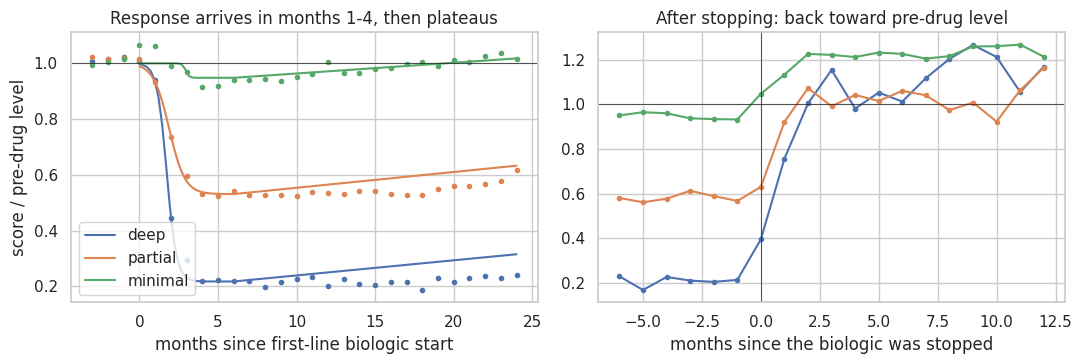

In [33]:
# plots
colors = {"deep": "C0", "partial": "C1", "minimal": "C2"}
fig, (ax_start, ax_stop) = plt.subplots(1, 2, figsize=(11, 3.8))
months = np.linspace(0, 24, 100)

for t in TYPES:
    # Left: observed monthly ratios (dots) and the fitted curve (line), months since START
    obs = tc_tab[(tc_tab.type == t) & (tc_tab.m <= 24)]
    ax_start.plot(obs.m, obs["mean"], "o", color=colors[t], ms=3)
    ax_start.plot(months, curve_value(months, T_["curves"][t]), color=colors[t], label=t)

    # Right: observed monthly ratios, months since STOP
    after_stop = ret_tab[ret_tab.type == t]
    ax_stop.plot(after_stop.ms, after_stop["mean"], "o-", color=colors[t], ms=3, label=t)

ax_start.axhline(1, color="k", lw=.5)
ax_start.set(xlabel="months since first-line biologic start", ylabel="score / pre-drug level",
             title="Response arrives in months 1-4, then plateaus")
ax_start.legend()

ax_stop.axvline(0, color="k", lw=.5)
ax_stop.axhline(1, color="k", lw=.5)
ax_stop.set(xlabel="months since the biologic was stopped",
            title="After stopping: back toward pre-drug level")
plt.tight_layout()

# checker
shares, mu = T_["mix"]["w"], T_["mix"]["mu"]
check("T4 treatment", "the three response types are ordered and the deep share is 5-20%",
      np.all(np.diff(mu) > 0) and 0.05 < shares[0] < 0.20, f"shares {shares.round(3)}")

t50 = {t: round(c["t50"], 2) for t, c in T_["curves"].items()}
check("T4 treatment", "response arrives in months 1-4 (half-response month between 1 and 4 for deep and partial)",
      all(1 <= T_["curves"][t]["t50"] <= 4 for t in ("deep", "partial")), t50)

check("T4 treatment", "after stopping the level is back to >= 90% of the pre-drug level (months 4+)",
      T_["rebound"] >= 0.9, f"{T_['rebound']:.2f}")

# 5 - treatment curve -- assembling parameters

In [54]:
# function helper -- analysis
def est_baseline(sc, hur, flare):
    # Scores while off biologic, summarised per patient (need >= 3 scores)
    off = sc[~sc.onb].groupby("patient_id").ihs4_score.agg(["mean", "var", "size"])
    off["H"] = hur.reindex(off.index)
    off = off[off["size"] >= 3].dropna(subset=["H"])

    stable_level = {}
    for h in (1, 2, 3):
        g = off[off.H == h]

        # Average score = stable level + average flare contribution -> subtract the flare part
        flare_part = flare["lam"][h] * flare["amp"] * flare["amp_scale"][h] * flare["tau"] / 365
        mean_level = g["mean"].mean() - flare_part

        # Spread of patient means = real between-patient spread + noise/n  -> remove the noise part
        between_var = max(g["mean"].var() - (g["var"] / g["size"]).mean(), 0.5)

        # Match a lognormal to that mean and variance
        s2 = np.log(1 + between_var / mean_level ** 2)
        stable_level[h] = (float(np.log(mean_level) - s2 / 2), float(np.sqrt(s2)))   # (mu, sigma)

    hurley_mix = {int(k): float(v) for k, v in hur.value_counts(normalize=True).items()}
    return stable_level, hurley_mix

def side_by_side(real, sim):
    return pd.DataFrame({"real B": real, "simulated": sim})

BASE, HMIX = est_baseline(sc_all[sc_all.patient_id.map(half)], HUR, FLARE)

print("stable level S (lognormal mu, sigma) by Hurley:", {h: tuple(round(x, 2) for x in v) for h, v in BASE.items()})
print("median S:", {h: round(float(np.exp(v[0])), 1) for h, v in BASE.items()})
print("Hurley mix:", {k: round(v, 2) for k, v in HMIX.items()})

stable level S (lognormal mu, sigma) by Hurley: {1: (1.67, 0.31), 2: (2.4, 0.24), 3: (2.97, 0.18)}
median S: {1: 5.3, 2: 11.0, 3: 19.6}
Hurley mix: {2: 0.46, 1: 0.3, 3: 0.25}


In [44]:
# function helpers -- flares analysis, simulation
def sig_(x):
    """Plain logistic: 1 / (1 + exp(-x)). (Same as logistic(x, midpoint=0, width=1).)"""
    return 1 / (1 + np.exp(-x))


def draw_flares(n, n_days, hurley, P, rng):
    """Random numbers that decide where flares happen and how big they are.
    Drawn ONCE per patient-day so the same flare chances are reused before and after a drug starts."""
    fl = P["flare"]
    u = rng.random((n, n_days), dtype=np.float32) # flare happens if u < rate
    amp = rng.gamma(fl["amp_shape"], 1.0 / fl["amp_shape"], (n, n_days)).astype(np.float32)   # random size, mean 1

    amp_by_patient = fl["amp"] * np.array([fl["amp_scale"][int(h)] for h in hurley], np.float32)
    amp *= amp_by_patient[:, None]  # scale to the real flare size

    rate = np.array([fl["lam"][int(h)] for h in hurley], np.float32) * P["hidden_mult"] / 365   # per day
    return u, amp, rate


def run_flares(u, amp, rate, fm, tau):
    """Turn flare onsets into a daily flare contribution: each flare jumps up, then decays with time constant tau.
    fm = flare-rate multiplier (1 = untreated, <1 = the drug reduces flares)."""
    n, n_days = u.shape
    onset = u < rate[:, None] * fm  # True on days a flare starts
    jumps = onset * amp
    decay = np.exp(-1 / tau)

    flare_extra = np.zeros((n, n_days), np.float32)
    current = np.zeros(n, np.float32)
    for t in range(n_days):
        current = current * decay + jumps[:, t] # yesterday's flares fade, today's add on
        flare_extra[:, t] = current
    return onset, flare_extra


def drug_progress(t, t0, ts, t50, w, tau_back):
    """How far the drug effect has developed: 0 = none, 1 = full.
    Logistic ramp after the start; after a stop, exponential decay back to 0."""
    months_since_start = (t[None, :] - t0[:, None]) / 30.4
    months_to_stop = (ts - t0)[:, None] / 30.4
    months_on = np.minimum(months_since_start, months_to_stop)              # clock freezes when the drug stops
    ramp = sig_((months_on + 0.5 - t50[:, None]) / w[:, None]) * (months_since_start >= 0)

    days_since_stop = np.maximum(t[None, :] - ts[:, None], 0)
    return ramp * np.exp(-days_since_stop / tau_back)


def draw_response(n, P, rng):
    """Draw each patient's response type and personal drug parameters."""
    T = P["treat"]
    names = np.array(T["names"])[rng.choice(3, n, p=T["mix"]["w"])]          # deep / partial / minimal

    def per_patient(key):                                                     # look up a parameter by type
        return np.array([T["curves"][x][key] for x in names])

    # Personal plateau = type's plateau x random factor (SD 0.25 on log scale)
    R = np.clip(per_patient("rho") * np.exp(0.25 * rng.standard_normal(n) - 0.03), 0.03, 1.3)

    hazard = np.array([T["stop_hazard"][x] for x in names])
    stop_after = rng.exponential(365 / np.maximum(hazard, 1e-4))              # days on drug until stopping

    return dict(type=names, R=R, t50=per_patient("t50"), w=per_patient("w"), drift=per_patient("drift_per_year"),
                fm=np.array([T["flare_mult"][x] for x in names]), stop_after=stop_after, tau_back=T["tau_back"])


def ratio_fm(p, resp, R=None):
    """Convert drug progress p into (activity multiplier, flare-rate multiplier).
    The slow upward drift is added separately by the caller."""
    R = resp["R"] if R is None else R
    ratio = 1 - (1 - R)[:, None] * p                                  # 1 -> R as the drug takes effect
    flare_mult = 1 + (resp["fm"] - 1)[:, None] * p                    # 1 -> type's flare multiplier
    return ratio, flare_mult


def noisy_score(A, P, rng):
    """Observed score = true activity + noise, rounded and clipped to 0-45. Noise variance grows with level."""
    var = P["noise"]["n0"] + P["noise"]["n1"] * np.clip(A, 0, None)
    return np.rint(np.clip(A + rng.standard_normal(A.shape) * np.sqrt(var), 0, 45))


def draw_S(hurley, P, rng):
    """Draw each patient's stable level from the lognormal of their Hurley stage."""
    mu = np.array([P["base"][int(h)][0] for h in hurley])
    sd = np.array([P["base"][int(h)][1] for h in hurley])
    return np.exp(mu + sd * rng.standard_normal(len(hurley)))


print("engine defined")

engine defined


In [45]:
# function helper -- hidden flare calibration

def first_bio(trt_):
    """Date each patient started their first biologic."""
    return trt_[trt_.treatment_class == "Biologic"].groupby("patient_id").start_date.min()


def untreated_scores(vis_, trt_, hur):
    """Scored visits from before each patient's first biologic."""
    s = mk_sc(vis_, trt_, hur)
    first = s.patient_id.map(first_bio(trt_)).fillna(pd.Timestamp("2100-01-01"))   # never treated -> keep all
    return s[s.visit_date < first].sort_values(["patient_id", "visit_date"])


def level_by_hurley(s):
    g = s.groupby("H").ihs4_score
    return pd.DataFrame({"mean": g.mean(), "sd": g.std(), "p10": g.quantile(.1), "p50": g.median(), "p90": g.quantile(.9)})


def semivariogram(s, bins=((0, 0), (1, 7), (8, 30), (31, 90), (91, 365))):
    """For every pair of scores of the SAME patient: half the squared difference, grouped by days apart.
    Close pairs differ only by noise; far pairs also differ by flares and drift."""
    lags, gammas = [], []
    for _, g in s.groupby("patient_id"):
        if len(g) < 2:
            continue
        days = g.visit_date.values.astype("datetime64[D]").astype(int)
        y = g.ihs4_score.values
        i, j = np.triu_indices(len(g), 1)                 # all pairs (i < j)
        lags.append(days[j] - days[i])
        gammas.append(0.5 * (y[j] - y[i]) ** 2)
    lags, gammas = np.concatenate(lags), np.concatenate(gammas)
    return pd.Series({f"{a}-{b} d": gammas[(lags >= a) & (lags <= b)].mean() for a, b in bins})


def regression_to_mean(s):
    """Patients picked for a high (or low) FIRST score: how much does their later score move without treatment?"""
    first = s.groupby("patient_id").first()                                 # first scored visit
    cutoffs = s.groupby("H").ihs4_score.quantile([.2, .8]).unstack()         # 20th / 80th percentile per stage

    # Mean score 30-180 days after the first visit, per patient
    withfirst = s.merge(first[["visit_date"]].rename(columns={"visit_date": "t_first"}),
                        left_on="patient_id", right_index=True)
    later = (withfirst[(withfirst.visit_date - withfirst.t_first).dt.days.between(30, 180)]
             .groupby("patient_id").ihs4_score.mean())

    first = first.join(later.rename("later"), how="inner")
    high = first.ihs4_score >= first.H.map(cutoffs[0.8])
    low  = first.ihs4_score <= first.H.map(cutoffs[0.2])
    return pd.Series({"high first score: later - first": (first[high].later - first[high].ihs4_score).mean(),
                      "low first score: later - first":  (first[low].later  - first[low].ihs4_score).mean(),
                      "n high": int(high.sum()), "n low": int(low.sum())})


def stats_untreated(vis_, trt_, hur):
    s = untreated_scores(vis_, trt_, hur)
    return {"level": level_by_hurley(s), "variogram": semivariogram(s), "rtm": regression_to_mean(s)}


def visits_per_patient_year(visits, demo):
    patient_years = (END - demo.diagnosis_date.clip(lower=START)).dt.days.sum() / 365.25
    return len(visits) / patient_years
vpy = visits_per_patient_year          # short name kept because later cells use it

In [47]:
# function helper -- simulate cohort

START = pd.Timestamp("2016-01-02")   # define this once, before PARAMS (see section 2)

def simulate_cohort(P, n=3000, seed=0):
    rng = np.random.default_rng(seed)
    n_days = (END - START).days + 1
    day = np.arange(n_days)
    dates = START + pd.to_timedelta(day, unit="D")
    patient_ids = np.array([f"S{i:05d}" for i in range(n)])
    vp = P["vis"]                                              # visit parameters

    # ---------- 1. Patients: Hurley stage, stable level, diagnosis day ----------
    probs = np.array([P["hmix"].get(k, 0) for k in (1, 2, 3)])
    hurley = rng.choice([1, 2, 3], n, p=probs / probs.sum())
    stable = draw_S(hurley, P, rng)                            # each patient's baseline activity
    diag_day = rng.choice(P["diag_days"], n)
    before_diag = day[None, :] < diag_day[:, None]             # (n, n_days) True = not diagnosed yet

    # ---------- 2. Flare chances (drawn once, reused before/after the drug) ----------
    u, amp, rate = draw_flares(n, n_days, hurley, P, rng)
    onset_untreated, _ = run_flares(u, amp, rate, np.ones((n, n_days), np.float32), P["flare"]["tau"])

    # ---------- 3. Who starts a first-line biologic, and when ----------
    # Sicker patients (Hurley 2-3, higher level) are more likely to start. Hurley 1 never does.
    log_s = np.log(stable)
    z = (log_s - log_s[hurley >= 2].mean()) / log_s[hurley >= 2].std()
    p_start = np.where(hurley >= 2, np.clip(0.5 + 0.2 * z, 0.05, 0.95), 0.0)
    start = np.full(n, -1)                                     # -1 = never starts

    for i in np.where(rng.random(n) < p_start)[0]:
        lo, hi = diag_day[i] + 180, n_days - 150               # allowed start window
        if hi <= lo:
            continue
        # Real data show drugs start near flares: pick a flare day + 0-14 days
        flare_days = (np.where(onset_untreated[i, lo:hi])[0] + lo) if P["start_at_flare"] else np.array([], int)
        if len(flare_days):
            start[i] = rng.choice(flare_days) + rng.integers(0, 15)
        else:
            start[i] = rng.integers(lo, hi)
    ever = start >= 0

    # ---------- 4. Drug effect over time ----------
    resp = draw_response(n, P, rng)                            # type, plateau, stop time, ...
    t_start = np.where(ever, start, n_days + 10_000)           # non-starters: "start" far in the future
    t_stop = np.where(ever, start + resp["stop_after"], n_days + 20_000)

    progress = drug_progress(day, t_start.astype(float), t_stop.astype(float),
                             resp["t50"], resp["w"], resp["tau_back"])   # 0 = no effect, 1 = full
    ratio, flare_mult = ratio_fm(progress, resp)               # activity multiplier, flare-rate multiplier

    months_since_start = (day[None, :] - t_start[:, None]) / 30.4
    ratio = np.clip(ratio + (resp["drift"] / 12)[:, None] * progress * np.maximum(months_since_start - 6, 0),
                    0.03, None)                                # slow drift upward after month 6

    flare_mult = np.where(ever[:, None], flare_mult, 1.0).astype(np.float32)   # non-starters: untouched
    ratio = np.where(ever[:, None], ratio, 1.0)

    # ---------- 5. Daily true activity = stable level x drug ratio + flares ----------
    onset, flare_extra = run_flares(u, amp, rate, flare_mult, P["flare"]["tau"])
    activity = (stable[:, None] * ratio + flare_extra).astype(np.float32)
    on_biologic = (day[None, :] >= t_start[:, None]) & (day[None, :] < t_stop[:, None])

    # ---------- 6. Treatment tables ----------
    # Antibiotic course = a flare that was "marked" (with hidden_mult > 1, some flares go unmarked)
    marked = onset & (rng.random((n, n_days), dtype=np.float32) < 1 / P["hidden_mult"])
    marked[before_diag] = False
    ab_pat, ab_day = np.nonzero(marked)

    abx = pd.DataFrame(dict(patient_id=patient_ids[ab_pat], treatment_class="Antibiotic", treatment_line=np.nan,
                            start_date=dates[ab_day], end_date=dates[ab_day] + pd.Timedelta(days=14)))
    bio = pd.DataFrame(dict(patient_id=patient_ids[ever], treatment_class="Biologic", treatment_line=1,
                            start_date=dates[start[ever]],
                            end_date=[dates[int(x)] if x < n_days else pd.NaT for x in t_stop[ever]]))

    # ---------- 7. Visits ----------
    # 7a. Routine visits: random in time, rate depends on Hurley stage and on/off biologic
    daily_rate = np.zeros((n, n_days), np.float32)
    for h in (1, 2, 3):
        for on in (0, 1):
            per_year = vp["visit_rate"].get((h, on), vp["visit_rate"].get((h, 0)))
            daily_rate[(hurley == h)[:, None] & (on_biologic == bool(on))] = per_year / 365
    daily_rate[before_diag] = 0
    v_pat, v_day = np.nonzero(rng.random((n, n_days), dtype=np.float32) < daily_rate)

    shares = vp["share_nonreactive"]
    v_type = rng.choice(list(shares.keys()), len(v_pat), p=np.array(list(shares.values())) / sum(shares.values()))

    # 7b. Reactive visits: some marked flares bring a visit within 0-7 days
    keep = rng.random(len(ab_pat)) < vp["p_react"]
    r_pat = ab_pat[keep]
    r_day = np.minimum(ab_day[keep] + rng.integers(0, 8, keep.sum()), n_days - 1)

    # ... and unmarked flares can bring one too (calibrated in section 5c)
    unmarked = onset & ~marked
    unmarked[before_diag] = False
    un_pat, un_day = np.nonzero(unmarked)
    keep_un = rng.random(len(un_pat)) < P.get("p_react_unmarked", 0.0)
    r_pat = np.concatenate([r_pat, un_pat[keep_un]])
    r_day = np.concatenate([r_day, np.minimum(un_day[keep_un] + rng.integers(0, 8, keep_un.sum()), n_days - 1)])

    V_pat = np.concatenate([v_pat, r_pat])
    V_day = np.concatenate([v_day, r_day])
    V_type = np.concatenate([v_type, np.full(len(r_pat), "flare_reactive")])

    # 7c. A few same-day duplicate visits (the real data have them; used to estimate noise)
    dup = rng.random(len(V_pat)) < P["p_same_day"]
    V_pat, V_day, V_type = (np.concatenate([a, a[dup]]) for a in (V_pat, V_day, V_type))

    # 7d. Is the visit scored? Depends on visit type and on the patient's clinic (site)
    site = rng.integers(0, P["n_sites"], n)
    site_offset = rng.standard_normal(P["n_sites"]) * (vp["practitioner_sd_prob"] / 0.23)   # 0.23 = hand-set conversion factor
    p_base = np.array([vp["p_score"][x] for x in V_type])
    p_scored = sig_(np.log(p_base / (1 - p_base)) + site_offset[site[V_pat]])   # shift on log-odds scale
    scored = rng.random(len(V_pat)) < p_scored

    # 7e. Observed score = true activity + noise, rounded; unscored visits get NaN
    score = noisy_score(activity[V_pat, V_day], P, rng)
    score[~scored] = np.nan

    # ---------- 8. Assemble the tables (same layout as the real data) ----------
    vis_ = (pd.DataFrame(dict(patient_id=patient_ids[V_pat], practitioner_id=[f"P{x:03d}" for x in site[V_pat]],
                              visit_date=dates[V_day], visit_type=V_type, ihs4_score=score))
              .sort_values(["patient_id", "visit_date"]).reset_index(drop=True))
    dem_ = pd.DataFrame(dict(patient_id=patient_ids, hurley_stage_baseline=hurley,
                             diagnosis_date=START + pd.to_timedelta(diag_day, unit="D")))
    trt_ = pd.concat([abx, bio], ignore_index=True)
    asg_ = pd.DataFrame(dict(patient_id=patient_ids, practitioner_id=[f"P{x:03d}" for x in site]))
    truth = pd.DataFrame(dict(patient_id=patient_ids, H=hurley, S=stable, started=ever,
                              type=np.where(ever, resp["type"], ""), R=np.where(ever, resp["R"], np.nan)))
    return dict(dem=dem_, trt=trt_, vis=vis_, asg=asg_, truth=truth)


def mk_sc(vis_, trt_, hur):
    """Scored visits only, plus: on-biologic flag, days from nearest antibiotic start, Hurley stage."""
    s = (vis_[vis_.ihs4_score.notna()][["patient_id", "visit_date", "visit_type", "ihs4_score"]]
         .reset_index(drop=True))
    s["onb"] = onbio_flag(s, trt_)
    s["rel"] = rel_to_antibiotic(s, trt_)
    s["H"] = s.patient_id.map(hur)
    return s

In [49]:
# Days from the first possible date to each patient's diagnosis, used to place diagnoses in the simulation
diag_days = (dem.diagnosis_date.clip(lower=START) - START).dt.days.clip(0, 3400).values

PARAMS = dict(
    # ---- estimated from half A of the real data ----
    noise=NOISE, flare=FLARE, vis=VIS, treat=TREAT, base=BASE, hmix=HMIX,
    # ---- ASSUMPTIONS (the data cannot identify them; vary them in the sensitivity analysis) ----
    hidden_mult=1.0,                       # flares per marked flare (1 = every flare gets an antibiotic course)
    placebo=dict(pi=0.10, t50=1.5, w=0.7), # placebo lowers level by pi, plateau; plausible range 0-0.25
    dropout_per_year=0.15,                 # trial drop-out; plausible range 0.05-0.35
    p_visit_done=0.95,                     # scheduled trial visit is attended and scored
    # ---- simulation settings ----
    p_same_day=0.01, p_react_unmarked=0.0, n_sites=60,
    diag_days=diag_days, start_at_flare=True, rebound=1.0)

In [50]:
# calibration loop for hidden flares
half_A_vis, half_A_dem = vis[vis.patient_id.map(half)], dem[dem.patient_id.map(half)]
ST_A = stats_untreated(half_A_vis, trt, HUR)                                      # real untreated statistics
R_react = VIS["reactive_share"] * vpy(half_A_vis, half_A_dem)                     # real reactive visits per patient-year
lam_mean = sum(PARAMS["hmix"].get(h, 0) * FLARE["lam"][h] for h in (1, 2, 3))     # average marked flares per patient-year

rows = []
for hm in (1.0, 1.5, 2.0, 2.5, 3.0, 4.0):               # candidate "true flares per marked flare"
    Q = dict(PARAMS, hidden_mult=hm)

    # Marked flares already give lam_mean * p_react reactive visits per year. The remainder must come from
    # unmarked flares, of which there are lam_mean * (hm - 1) per year -> chance an unmarked flare brings a visit.
    if hm > 1:
        Q["p_react_unmarked"] = float(np.clip((R_react - lam_mean * VIS["p_react"]) / (lam_mean * (hm - 1)), 0, 1))
    else:
        Q["p_react_unmarked"] = 0.0

    sim = simulate_cohort(Q, n=2500, seed=5)
    st = stats_untreated(sim["vis"], sim["trt"], sim["dem"].set_index("patient_id").hurley_stage_baseline)

    # How far is the simulated semivariogram from the real one? (lags >= 1 day; squared relative error)
    error = float(((st["variogram"].iloc[1:] / ST_A["variogram"].iloc[1:] - 1) ** 2).sum())
    rows.append(dict(hidden_mult=hm, p_react_unmarked=Q["p_react_unmarked"], semivariogram_error=error,
                     visits_per_patient_year=vpy(sim["vis"], sim["dem"]),
                     **{f"lag {k}": v for k, v in st["variogram"].iloc[1:].items()}))

CAL = pd.DataFrame(rows)
print("real half A semivariogram:", ST_A["variogram"].round(2).to_dict())
print(f"reactive visits per patient-year {R_react:.2f} | real visits per patient-year {vpy(half_A_vis, half_A_dem):.1f}")
print(CAL.round(2).to_string(index=False))

best = CAL.loc[CAL.semivariogram_error.idxmin()]
PARAMS["hidden_mult"] = float(best.hidden_mult)
PARAMS["p_react_unmarked"] = float(best.p_react_unmarked)
print(f"chosen: hidden_mult = {PARAMS['hidden_mult']}, p_react_unmarked = {PARAMS['p_react_unmarked']:.2f}")

SIM = simulate_cohort(PARAMS, n=3000, seed=1)       # regenerate with the chosen values

check("T3b hidden flares",
      "the data need MORE flares than antibiotic courses mark (hidden_mult > 1); which mechanism is UNDETERMINED",
      PARAMS["hidden_mult"] > 1, f"hidden_mult = {PARAMS['hidden_mult']}", warn=True)

real half A semivariogram: {'0-0 d': 1.99, '1-7 d': 6.89, '8-30 d': 10.67, '31-90 d': 15.07, '91-365 d': 16.5}
reactive visits per patient-year 1.51 | real visits per patient-year 7.0
 hidden_mult  p_react_unmarked  semivariogram_error  visits_per_patient_year  lag 1-7 d  lag 8-30 d  lag 31-90 d  lag 91-365 d
         1.0              0.00                 0.34                     3.23       5.31        8.55        10.06         10.32
         1.5              0.76                 0.02                     4.04       6.26       11.35        14.85         15.31
         2.0              0.38                 0.03                     4.02       6.82       12.39        15.67         16.46
         2.5              0.25                 0.17                     4.01       6.81       14.59        17.56         18.00
         3.0              0.19                 0.20                     4.02       7.73       14.48        17.97         18.85
         4.0              0.13                 0.28   

In [ ]:
# check simulated cohort
t_begin = time.time()
SIM = simulate_cohort(PARAMS, n=3000, seed=1)

print(f"simulated cohort in {time.time() - t_begin:.0f}s: {len(SIM['dem'])} patients, {len(SIM['vis'])} visits "
      f"({SIM['vis'].ihs4_score.notna().mean():.0%} scored), "
      f"{(SIM['trt'].treatment_class == 'Biologic').sum()} biologic starts, "
      f"{(SIM['trt'].treatment_class == 'Antibiotic').sum()} antibiotic courses")
print("real, for comparison: 64% scored; 0.78 biologic lines per patient; 8.9 antibiotic courses per patient")

simulated cohort in 4s: 3000 patients, 58468 visits (64% scored), 908 biologic starts, 30552 antibiotic courses
real, for comparison: 64% scored; 0.78 biologic lines per patient; 8.9 antibiotic courses per patient


# 6 - discontinuation and placebo

In [52]:
# function helper -- recover

def recover(sim, P):
    hur = sim["dem"].set_index("patient_id").hurley_stage_baseline
    sc = mk_sc(sim["vis"], sim["trt"], hur)

    noise, _ = est_noise(sc)
    flare, _, _ = est_flare(sc, sim["trt"], sim["dem"], hur)
    visits = est_visits(sim["vis"], sim["trt"], sim["dem"], sim["asg"], hur)
    treat, _, _, _ = est_treatment(sim["vis"], sim["trt"], sim["dem"], hur)

    # (name, truth, recovered)
    rows = [
        ("noise n0",                    P["noise"]["n0"], noise["n0"]),
        ("noise variance at level 10",  P["noise"]["n0"] + 10 * P["noise"]["n1"], noise["n0"] + 10 * noise["n1"]),
        ("flare tau (d)",               P["flare"]["tau"], flare["tau"]),
        ("flare amplitude",             P["flare"]["amp"], flare["amp"]),
        ("flares/yr Hurley 2",          P["flare"]["lam"][2], flare["lam"][2]),
        ("flares/yr Hurley 3",          P["flare"]["lam"][3], flare["lam"][3]),
        ("P(reactive visit | flare)",   P["vis"]["p_react"], visits["p_react"]),
        ("site SD of scoring prob",     P["vis"]["practitioner_sd_prob"], visits["practitioner_sd_prob"]),
        ("scored share, follow_up",     P["vis"]["p_score"]["follow_up"], visits["p_score"]["follow_up"]),
    ]
    for k, name in enumerate(P["treat"]["names"]):
        rows += [
            (f"share {name}",         P["treat"]["mix"]["w"][k],            treat["mix"]["w"][k]),
            (f"plateau ratio {name}", P["treat"]["curves"][name]["rho"],    treat["curves"][name]["rho"]),
            (f"stops/yr {name}",      P["treat"]["stop_hazard"][name],      treat["stop_hazard"][name]),
        ]
    rows.append(("return time constant (d)", P["treat"]["tau_back"], treat["tau_back"]))

    out = pd.DataFrame(rows, columns=["parameter", "truth", "recovered"])
    out["rel_error"] = (out.recovered - out.truth) / out.truth.abs()
    return out

In [56]:
# function helper -- first line starter
def stats_starters(vis_, trt_, hur):
    line1 = trt_[(trt_.treatment_class == "Biologic") & (trt_.treatment_line == 1)].set_index("patient_id")

    scores = vis_[vis_.ihs4_score.notna()].join(line1.start_date.rename("t0"), on="patient_id", how="inner")
    scores["d"] = (scores.visit_date - scores.t0).dt.days            # days since the drug started

    def level(mask):
        return scores[mask].groupby("patient_id").ihs4_score.agg(["mean", "size"])

    pre = level((scores.d < 0) & (scores.d >= -365))                 # the year before
    on = level((scores.d >= 90) & (scores.d <= 365))                 # months 3-12 on drug

    r = pre.join(on, lsuffix="_p", rsuffix="_o", how="inner")
    r = r[(r.size_p >= 2) & (r.size_o >= 2) & (r.mean_p >= 3)]       # enough scores, real baseline activity
    r["ratio"] = r.mean_o / r.mean_p                                 # <1 = improved
    r["H"] = hur.reindex(r.index)
    r = r[r.H.isin([2, 3])]

    # Share who stopped within a year, among lines that started at least a year before the data end
    eligible = line1[line1.start_date <= END - pd.Timedelta(days=365)]
    stopped_in_year = eligible.end_date.notna() & ((eligible.end_date - eligible.start_date).dt.days < 365)

    return pd.Series({
        "n starters with pre and on scores": len(r),
        "median on/pre ratio": r.ratio.median(),
        "IQR low (25%)": r.ratio.quantile(.25),
        "IQR high (75%)": r.ratio.quantile(.75),
        "share with ratio < 0.5": (r.ratio < 0.5).mean(),
        "share with ratio > 0.9": (r.ratio > 0.9).mean(),
        "stopped within 12 months": stopped_in_year.mean()})

In [53]:
# look for how much tructh the estimator recover

REC = recover(SIM, PARAMS)
print(REC.round(3).to_string(index=False))

too_far = REC[REC.rel_error.abs() > 0.30]
# First 9 rows = noise, flare, visit parameters; exclude "site SD" (only 60 sites in the simulation)
core = REC.iloc[:9][REC.iloc[:9].parameter != "site SD of scoring prob"]
worst = core.loc[core.rel_error.abs().idxmax()]
plateaus = REC[REC.parameter.str.startswith("plateau")]

check("V1 recovery",
      "estimators recover noise, flare decay and visit parameters within 30% (site SD of scoring prob excluded: sites are only 60 in the simulation)",
      core.rel_error.abs().max() < 0.30, f"worst: {worst.parameter} ({abs(worst.rel_error):.0%})", warn=True)
check("V1 recovery",
      "estimators recover the response-type plateaus within 30% (start-at-flare bias included)",
      plateaus.rel_error.abs().max() < 0.30, f"max rel error {plateaus.rel_error.abs().max():.0%}", warn=True)
check("V1 recovery", "parameters that fail the 30% bar are listed, not hidden", True,
      ", ".join(too_far.parameter) if len(too_far) else "none")

                 parameter  truth  recovered  rel_error
                  noise n0  2.017      2.210      0.096
noise variance at level 10  2.057      2.131      0.036
             flare tau (d) 15.404     24.911      0.617
           flare amplitude  4.907      4.337     -0.116
        flares/yr Hurley 2  2.389      2.401      0.005
        flares/yr Hurley 3  2.521      2.548      0.011
 P(reactive visit | flare)  0.340      0.378      0.113
   site SD of scoring prob  0.175      0.158     -0.096
   scored share, follow_up  0.676      0.667     -0.012
                share deep  0.154      0.182      0.186
        plateau ratio deep  0.218      0.271      0.244
             stops/yr deep  0.055      0.035     -0.363
             share partial  0.302      0.334      0.105
     plateau ratio partial  0.531      0.572      0.076
          stops/yr partial  0.115      0.129      0.116
             share minimal  0.544      0.484     -0.111
     plateau ratio minimal  0.948      1.036    

LEVEL by Hurley, real half B:
     mean    sd   p10   p50   p90
H                               
1   6.10  3.44   2.0   6.0  11.0
2  12.40  4.88   7.0  12.0  19.0
3  21.54  6.07  15.0  21.0  30.0
LEVEL by Hurley, simulated:
     mean    sd   p10   p50   p90
H                               
1   6.71  3.05   3.0   6.0  11.0
2  13.14  4.32   8.0  12.0  19.0
3  23.17  6.21  17.0  22.0  32.0

SEMIVARIOGRAM (half squared score difference by lag):
           real B  simulated
0-0 d       2.04       2.23
1-7 d       7.12       6.67
8-30 d     10.99      11.87
31-90 d    15.18      14.35
91-365 d   16.57      14.66

REGRESSION TO THE MEAN (no treatment):
                                   real B  simulated
high first score: later - first    -4.01      -3.45
low first score: later - first      4.09       2.83
n high                            316.00     406.00
n low                            2325.00     491.00
PASS | V2 untreated | mean score by Hurley within 15% of held-out real | max differen

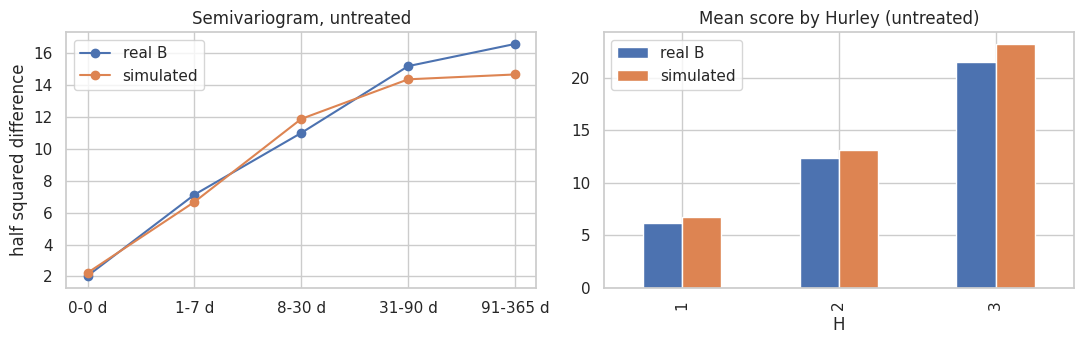

In [55]:
# simulated vs. real held-out patients

ST_real = stats_untreated(vis[vis.patient_id.map(~half)], trt, HUR)               # real half B (never used for fitting)
ST_sim = stats_untreated(SIM["vis"], SIM["trt"], SIM["dem"].set_index("patient_id").hurley_stage_baseline)

print("LEVEL by Hurley, real half B:\n", ST_real["level"].round(2).to_string())
print("LEVEL by Hurley, simulated:\n", ST_sim["level"].round(2).to_string())
print("\nSEMIVARIOGRAM (half squared score difference by lag):\n",
      side_by_side(ST_real["variogram"], ST_sim["variogram"]).round(2).to_string())
print("\nREGRESSION TO THE MEAN (no treatment):\n",
      side_by_side(ST_real["rtm"], ST_sim["rtm"]).round(2).to_string())

# graph
fig, (ax_vg, ax_lv) = plt.subplots(1, 2, figsize=(11, 3.6))
side_by_side(ST_real["variogram"], ST_sim["variogram"]).plot(marker="o", ax=ax_vg, title="Semivariogram, untreated")
ax_vg.set_ylabel("half squared difference")
side_by_side(ST_real["level"]["mean"], ST_sim["level"]["mean"]).plot.bar(ax=ax_lv, title="Mean score by Hurley (untreated)")
plt.tight_layout()

# Checkers
HI = "high first score: later - first"
level_diff = (ST_sim["level"]["mean"] / ST_real["level"]["mean"] - 1).abs()
vario_diff = (ST_sim["variogram"] / ST_real["variogram"] - 1).abs()
rtm_ratio = ST_sim["rtm"][HI] / ST_real["rtm"][HI]
check("V2 untreated", "mean score by Hurley within 15% of held-out real",
      level_diff.max() < 0.15, f"max difference {level_diff.max():.0%}", warn=True)
check("V2 untreated", "semivariogram within 25% of held-out real at every lag",
      vario_diff.max() < 0.25, f"max difference {vario_diff.max():.0%} at lag {vario_diff.idxmax()}", warn=True)
check("V2 untreated", "regression to the mean has the right sign and size (0.6-1.6 x real)",
      ST_sim["rtm"][HI] < 0 and 0.6 < rtm_ratio < 1.6,
      f"simulated {ST_sim['rtm'][HI]:.2f} vs real {ST_real['rtm'][HI]:.2f}", warn=True)

real_vpy, sim_vpy = vpy(vis, dem), vpy(SIM["vis"], SIM["dem"])
print(f"\nvisits per patient-year: real {real_vpy:.1f}, simulated {sim_vpy:.1f}")
check("V2 untreated", "visit frequency matches (informative visiting is modelled)",
      abs(sim_vpy / real_vpy - 1) < 0.25, f"real {real_vpy:.1f} vs simulated {sim_vpy:.1f} per patient-year", warn=True)

In [57]:
# first line starters, simulated vs. real
SS_real = stats_starters(vis[vis.patient_id.map(~half)], trt, HUR)
SIM2 = simulate_cohort(PARAMS, n=6000, seed=7)
SS_sim = stats_starters(SIM2["vis"], SIM2["trt"], SIM2["dem"].set_index("patient_id").hurley_stage_baseline)

cmp3 = pd.DataFrame({"real half B": SS_real, "simulated": SS_sim})
print(cmp3.round(3).to_string())

rel_diff = (cmp3["simulated"] / cmp3["real half B"] - 1).abs().drop("n starters with pre and on scores")
main = ["median on/pre ratio", "share with ratio < 0.5", "stopped within 12 months"]
spread = ["IQR low (25%)", "IQR high (75%)"]
check("V3 starters", "median on/pre ratio, share responding >= 50% and stop rate within 25% of held-out real",
      rel_diff[main].max() < 0.25, rel_diff[main].round(2).to_dict(), warn=True)
check("V3 starters", "spread of the response (IQR) matches within 25%",
      rel_diff[spread].max() < 0.25, rel_diff[spread].round(2).to_dict(), warn=True)

                                   real half B  simulated
n starters with pre and on scores     3345.000    990.000
median on/pre ratio                      0.736      0.796
IQR low (25%)                            0.533      0.528
IQR high (75%)                           0.924      1.034
share with ratio < 0.5                   0.220      0.223
share with ratio > 0.9                   0.275      0.383
stopped within 12 months                 0.212      0.181
PASS | V3 starters | median on/pre ratio, share responding >= 50% and stop rate within 25% of held-out real | {'median on/pre ratio': 0.08, 'share with ratio < 0.5': 0.02, 'stopped within 12 months': 0.15}
PASS | V3 starters | spread of the response (IQR) matches within 25% | {'IQR low (25%)': 0.01, 'IQR high (75%)': 0.12}


# 7 - simulator

In [62]:
# trial simulator

def simulate_trial(P, n_per_arm, design=None, seed=0):
    # Design options (override any of them via `design`) 
    D = dict(hurley=(2, 3), # Hurley stages allowed in the trial
             thr=None, # screening threshold (None = no screening)
             rule="mean2",                   # "mean2": mean of 2 screening scores; "single": last score only
             weeks=(4, 8, 12, 16, 20, 24), # scheduled visit weeks
             effect_scale=1.0) # multiplies the true drug effect (1 = as estimated)
    D.update(design or {})

    rng = np.random.default_rng(seed)
    SCREEN_1, SCREEN_2 = 62, 90 # day index of the two screening scores (day -28 and day 0)
    DAY0 = 90 # day index of randomization (we simulate 90 days before)
    n_days = DAY0 + 7 * 26 + 8
    day = np.arange(n_days) - DAY0 # days relative to randomization: -90 ... +189
    n_needed = 2 * n_per_arm

    stages = list(D["hurley"])
    stage_probs = np.array([P["hmix"][h] for h in stages], float)
    stage_probs /= stage_probs.sum()

    batches = [] # eligible patients collected so far
    n_candidates = n_eligible = 0

    # Keep drawing batches of candidates until enough pass screening 
    while n_eligible < n_needed:
        # Batch size: enough to finish, based on the pass rate seen so far (guess 1/3 on the first batch)
        pass_rate_guess = n_eligible / n_candidates if n_candidates else 1 / 3
        m = max(2000, int(1.4 * (n_needed - n_eligible) / pass_rate_guess)) if n_candidates else \
            max(2000, int(1.4 * (n_needed - n_eligible) * 3))
        # (the original: m = max(2000, int(1.4 * remaining * (n_candidates / max(n_eligible, 1) if n_candidates else 3))))

        # Step 1: candidates 
        hurley = rng.choice(stages, m, p=stage_probs)
        stable = draw_S(hurley, P, rng) # baseline activity
        u, amp, rate = draw_flares(m, n_days, hurley, P, rng)  # flare chances, shared by both arms
        resp = draw_response(m, P, rng)   # response type etc. (used for the active arm)

        # Step 2a: activity ratio if on the ACTIVE drug (starting at day 0)
        start0 = np.zeros(m)
        progress = drug_progress(day.astype(float), start0, resp["stop_after"],
                                 resp["t50"], resp["w"], resp["tau_back"])
        ratio, flare_mult = ratio_fm(progress, resp)
        months = day[None, :] / 30.4
        ratio = np.clip(ratio + (resp["drift"] / 12)[:, None] * progress * np.maximum(months - 6, 0), 0.03, None)

        # effect_scale = 1 keeps the estimated effect; 0.7 / 1.3 weaken / strengthen it
        es = D["effect_scale"]
        ratio_active = 1 - es * (1 - ratio)
        flare_mult_active = (1 + es * (flare_mult - 1)).astype(np.float32)

        # Step 2b: activity ratio if on PLACEBO (a small dip with a plateau, no flare change)
        pl = P["placebo"]
        ratio_placebo = 1 - pl["pi"] * sig_((months + 0.5 - pl["t50"]) / pl["w"]) * (day[None, :] >= 0)

        # Step 2c: true daily activity under each arm (same flare chances u, amp)
        _, flares_active = run_flares(u, amp, rate, flare_mult_active, P["flare"]["tau"])
        _, flares_placebo = run_flares(u, amp, rate, np.ones((m, n_days), np.float32), P["flare"]["tau"])
        activity_active = stable[:, None] * ratio_active + flares_active
        activity_placebo = stable[:, None] * np.broadcast_to(ratio_placebo, (m, n_days)) + flares_placebo

        # Step 3: two noisy screening scores, measured before any treatment
        untreated = stable[:, None] + flares_placebo
        s1 = noisy_score(untreated[:, SCREEN_1], P, rng)
        s0 = noisy_score(untreated[:, SCREEN_2], P, rng)
        baseline = (s1 + s0) / 2

        if D["thr"] is None:
            eligible = np.ones(m, bool)
        elif D["rule"] == "mean2":
            eligible = baseline >= D["thr"]
        else:
            eligible = s0 >= D["thr"]

        n_candidates += m
        n_eligible += eligible.sum()
        batches.append(dict(H=hurley[eligible], S=stable[eligible], s1=s1[eligible], s0=s0[eligible],
                            Aa=activity_active[eligible], Ap=activity_placebo[eligible]))

    def stack(key): # join the batches, keep exactly n_needed
        return np.concatenate([b[key] for b in batches])[:n_needed]

    hurley = stack("H")
    activity_active, activity_placebo = stack("Aa"), stack("Ap")

    # Step 4: 1:1 randomization within each Hurley stage
    arm = np.zeros(n_needed, int)                                # 1 = active, 0 = control
    for h in stages:
        idx = rng.permutation(np.where(hurley == h)[0])
        arm[idx[: len(idx) // 2]] = 1

    # Step 5: scheduled visits, noisy scores, drop-outs and missed visits
    activity = np.where(arm[:, None] == 1, activity_active, activity_placebo)
    weeks = list(D["weeks"])
    scores = np.column_stack([noisy_score(activity[:, DAY0 + 7 * w], P, rng) for w in weeks])

    drop_day = rng.exponential(365 / P["dropout_per_year"], n_needed)
    after_dropout = np.array(weeks)[None, :] * 7 >= drop_day[:, None]
    missed_visit = rng.random(scores.shape) > P["p_visit_done"]
    scores[after_dropout | missed_visit] = np.nan

    df = pd.DataFrame(scores, columns=[f"w{w}" for w in weeks])
    df.insert(0, "arm", arm)
    df.insert(1, "H", hurley)
    df["s1"], df["s0"] = stack("s1"), stack("s0")
    df["baseline"] = (df.s1 + df.s0) / 2
    df["dropped"] = drop_day < 7 * max(weeks)
    df.attrs["pass_rate"] = n_eligible / n_candidates  # share of candidates who passed screening
    return df

In [69]:
# function helper -- analysis

def endpoint(df, kind):
    """The outcome per patient: a single week, or the mean of several scheduled scores (missing ones ignored)."""
    week_cols = [c for c in df.columns if c.startswith("w") and c[1:].isdigit()]
    wanted = {"wk16": [16], "mean12_16": [12, 16], "mean8_24": [w for w in range(8, 25)]}[kind]
    cols = [c for c in week_cols if int(c[1:]) in wanted]
    return df[cols].mean(axis=1) if cols else pd.Series(np.nan, index=df.index)


def ols(df, y, adjust):
    """Treatment effect by least squares. Returns (effect in points, + = better), SE, residual variance, n.
    adjust=True adds baseline score and Hurley stage 3 as covariates (ANCOVA)."""
    d = df.assign(y=y).dropna(subset=["y"])
    columns = [np.ones(len(d)), d.arm.values]                      # intercept, arm
    if adjust:
        columns += [d.baseline.values, (d.H.values == 3).astype(float)]
    X = np.column_stack(columns)

    beta, *_ = np.linalg.lstsq(X, d.y.values, rcond=None)
    resid = d.y.values - X @ beta
    resid_var = resid @ resid / (len(d) - X.shape[1])
    se = np.sqrt(resid_var * np.linalg.inv(X.T @ X)[1, 1])         # SE of the arm coefficient
    return -beta[1], se, resid_var, len(d)                         # lower score = better, so flip the sign


def analyses(df, kind):
    y = endpoint(df, kind)
    return {"post-only (no baseline)": ols(df, y, False),
            "change from baseline":    ols(df, y - df.baseline, False),
            "ANCOVA (baseline + Hurley)": ols(df, y, True)}


def n_required(effect, resid_var, alpha=0.05, power=0.8):
    """Patients per arm: 2 * variance * (z_alpha/2 + z_power)^2 / effect^2."""
    z = stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(power)
    return 2 * resid_var * z ** 2 / effect ** 2


def design_row(P, design, kind, n_big=3000, seed=11, df=None):
    """Simulate one large trial for a design and turn it into sample-size numbers."""
    if df is None:
        df = simulate_trial(P, n_big, design, seed)
    results = analyses(df, kind)
    effect, _, var, _ = results["ANCOVA (baseline + Hurley)"]
    effect_cs, _, var_cs, _ = results["change from baseline"]
    pass_rate = df.attrs["pass_rate"]

    # Responder endpoint: score <= 45% of baseline (i.e. at least 55% reduction)
    y = endpoint(df, kind)
    responder = (y <= 0.45 * df.baseline).fillna(False)
    p1, p0 = responder[df.arm == 1].mean(), responder[df.arm == 0].mean()
    z = stats.norm.ppf(.975) + stats.norm.ppf(.8)
    n_binary = z ** 2 * (p1 * (1 - p1) + p0 * (1 - p0)) / max(p1 - p0, 1e-6) ** 2

    n_ancova = n_required(effect, var)
    return dict(effect_points=effect, sd_ancova=np.sqrt(var),
                n_per_arm_ANCOVA=n_ancova, n_per_arm_change_score=n_required(effect_cs, var_cs),
                n_per_arm_IHS4_55=n_binary, pass_rate=pass_rate,
                screened_for_ANCOVA_trial=2 * n_ancova / pass_rate,
                dropout=float(df.dropped.mean()), p_active=p1, p_control=p0)

def mc_power(P, design, n, reps=500, seed0=100):
    """Run `reps` full trials of n per arm. Returns (share with p < 0.05, mean estimated effect, SD of estimates)."""
    n_reject, effects = 0, []
    for k in range(reps):
        df = simulate_trial(P, n, design, seed0 + k)
        effect, se, _, _ = ols(df, endpoint(df, "mean8_24"), True)
        n_reject += abs(effect / se) > 1.96
        effects.append(effect)
    return n_reject / reps, float(np.mean(effects)), float(np.std(effects))

print("simulator ready")

simulator ready


4000 per arm, no enrichment, week-16 single score
  control: baseline 15.2 -> week 16 13.7
  active:  baseline 15.2 -> week 16 11.1
  drop-out by week 24: 7%
                            effect (points, +=better)     SE  residual variance  n analysed
post-only (no baseline)                         2.652  0.146             38.891      7288.0
change from baseline                            2.678  0.116             24.357      7288.0
ANCOVA (baseline + Hurley)                      2.673  0.109             21.546      7288.0
PASS | T5 trial | control arm improves a little with no drug (placebo + regression to the mean + natural flare decay) | 15.2 -> 13.7
PASS | T5 trial | active arm improves more than control, and ANCOVA has a smaller residual variance than post-only | effect 2.67 points; variance 21.5 vs 38.9


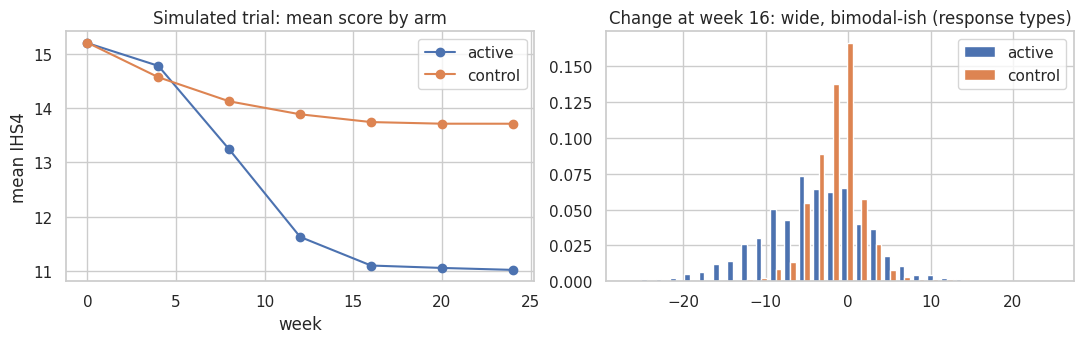

In [65]:
# check before the simulated trial

big = simulate_trial(PARAMS, 4000, dict(thr=None), seed=3)
res = analyses(big, "wk16")
active, control = big[big.arm == 1], big[big.arm == 0]

print(f"4000 per arm, no enrichment, week-16 single score")
print(f"  control: baseline {control.baseline.mean():.1f} -> week 16 {control.w16.mean():.1f}")
print(f"  active:  baseline {active.baseline.mean():.1f} -> week 16 {active.w16.mean():.1f}")
print(f"  drop-out by week 24: {big.dropped.mean():.0%}")
print(pd.DataFrame(res, index=["effect (points, +=better)", "SE", "residual variance", "n analysed"]).T.round(3).to_string())

# graph
week_cols = [c for c in big.columns if c.startswith("w") and c[1:].isdigit()]
week_nums = [int(c[1:]) for c in week_cols]
fig, (ax_mean, ax_change) = plt.subplots(1, 2, figsize=(11, 3.6))

for group, name in ((active, "active"), (control, "control")):
    ax_mean.plot([0] + week_nums, [group.baseline.mean()] + [group[c].mean() for c in week_cols], "o-", label=name)
ax_mean.set(xlabel="week", ylabel="mean IHS4", title="Simulated trial: mean score by arm")
ax_mean.legend()

change = big.w16 - big.baseline
ax_change.hist([change[big.arm == 1].dropna(), change[big.arm == 0].dropna()],
               bins=30, label=["active", "control"], density=True)
ax_change.set_title("Change at week 16: wide, bimodal-ish (response types)")
ax_change.legend()
plt.tight_layout()

# ---------- Checks ----------
ancova = res["ANCOVA (baseline + Hurley)"]
post_only = res["post-only (no baseline)"]
check("T5 trial", "control arm improves a little with no drug (placebo + regression to the mean + natural flare decay)",
      control.w16.mean() < control.baseline.mean(), f"{control.baseline.mean():.1f} -> {control.w16.mean():.1f}")
check("T5 trial", "active arm improves more than control, and ANCOVA has a smaller residual variance than post-only",
      ancova[0] > 0 and ancova[2] < post_only[2],
      f"effect {ancova[0]:.2f} points; variance {ancova[2]:.1f} vs {post_only[2]:.1f}")

In [66]:
# endpoint and visit schedule

EVERY_4 = (4, 8, 12, 16, 20, 24)
designs = [  # (label, visit weeks, endpoint)
    ("week-16 single score, schedule every 4 wk", EVERY_4,                 "wk16"),
    ("week-16 single score, only week 16",        (16,),                   "wk16"),
    ("mean of weeks 12 and 16, every 4 wk",       EVERY_4,                 "mean12_16"),
    ("mean of weeks 8-24, every 4 wk",            EVERY_4,                 "mean8_24"),
    ("mean of weeks 8, 16, 24, every 8 wk",       (8, 16, 24),             "mean8_24"),
    ("mean of weeks 8-24, every 2 wk",            tuple(range(2, 25, 2)),  "mean8_24"),
]

keep = ["effect_points", "sd_ancova", "n_per_arm_ANCOVA", "n_per_arm_change_score", "n_per_arm_IHS4_55"]
rows = []
for label, schedule, kind in designs:
    r = design_row(PARAMS, dict(weeks=schedule), kind)
    rows.append(dict(design=label, n_visits=len(schedule), **{k: r[k] for k in keep}))

ENDP = pd.DataFrame(rows).round(2)
print(ENDP.to_string(index=False))

n_by_design = ENDP.set_index("design").n_per_arm_ANCOVA
n_single, n_mean = n_by_design["week-16 single score, only week 16"], n_by_design["mean of weeks 8-24, every 4 wk"]
check("T6 design", "averaging several scheduled scores needs fewer patients than one week-16 score (noise is large)",
      n_mean + 1 < n_single, f"{n_mean:.0f} vs {n_single:.0f} per arm")
check("T6 design", "ANCOVA needs fewer patients than change-from-baseline (baseline is a noisy covariate)",
      ENDP.n_per_arm_ANCOVA.mean() < ENDP.n_per_arm_change_score.mean(),
      f"mean {ENDP.n_per_arm_ANCOVA.mean():.0f} vs {ENDP.n_per_arm_change_score.mean():.0f}")

                                   design  n_visits  effect_points  sd_ancova  n_per_arm_ANCOVA  n_per_arm_change_score  n_per_arm_IHS4_55
week-16 single score, schedule every 4 wk         6           2.34       4.76             65.15                   75.64              30.47
       week-16 single score, only week 16         1           2.35       4.75             64.43                   73.45              32.56
      mean of weeks 12 and 16, every 4 wk         6           2.18       4.17             57.46                   68.21              33.97
           mean of weeks 8-24, every 4 wk         6           1.98       3.72             55.63                   68.95              40.72
      mean of weeks 8, 16, 24, every 8 wk         3           1.79       3.68             65.93                   80.77              46.89
           mean of weeks 8-24, every 2 wk        12           2.05       3.74             52.26                   63.59              38.40
PASS | T6 design | averagin

In [67]:
# enrichment / screening treshold

rows = []
for rule in ("mean2", "single"):
    for thr in (None, 6, 9, 12, 15):
        if thr is None and rule == "single":
            continue                                   # "no screening" is the same under both rules

        design = dict(thr=thr, rule=rule)
        df = simulate_trial(PARAMS, 3000, design, seed=11)
        r = design_row(PARAMS, design, "mean8_24", df=df)

        # Control arm: change from the score(s) used for selection to the outcome
        control = df[df.arm == 0]
        selecting_score = control.s0 if (rule == "single" and thr is not None) else control.baseline
        control_change = (endpoint(control, "mean8_24") - selecting_score).mean()

        if thr is None:
            label = "none"
        else:
            label = f"{'mean of 2 scores' if rule == 'mean2' else 'single score'} >= {thr}"

        rows.append(dict(screening=label, pass_rate=r["pass_rate"], effect_points=r["effect_points"],
                         sd_ancova=r["sd_ancova"], n_per_arm=r["n_per_arm_ANCOVA"],
                         patients_to_screen=r["screened_for_ANCOVA_trial"], control_arm_change=control_change))

ENR = pd.DataFrame(rows).round(2)
print(ENR.to_string(index=False))

single_change = ENR[ENR.screening.str.startswith("single")].control_arm_change.mean()
mean2_change = ENR[ENR.screening.str.startswith("mean of 2")].control_arm_change.mean()
check("T6 design",
      "control-arm drop from the SELECTING score is larger when selecting on one score than on the mean of two (regression to the mean)",
      single_change < mean2_change,
      f"control-arm change from the selecting score(s): single {single_change:.2f} vs mean of two {mean2_change:.2f}")

none_row = ENR[ENR.screening == "none"].iloc[0]
strict_row = ENR[ENR.screening == "mean of 2 scores >= 15"].iloc[0]
check("T6 design", "enrichment reduces the sample size per arm, but increases the number to screen",
      strict_row.n_per_arm < none_row.n_per_arm and strict_row.patients_to_screen > strict_row.n_per_arm * 2,
      f"n/arm {none_row.n_per_arm:.0f} -> {strict_row.n_per_arm:.0f}; screened {strict_row.patients_to_screen:.0f}", warn=True)

             screening  pass_rate  effect_points  sd_ancova  n_per_arm  patients_to_screen  control_arm_change
                  none       1.00           1.98       3.72      55.63              111.25               -1.38
 mean of 2 scores >= 6       0.99           2.11       3.71      48.63               97.79               -1.38
 mean of 2 scores >= 9       0.90           2.16       3.83      49.56              109.76               -1.60
mean of 2 scores >= 12       0.66           2.47       4.18      45.03              136.59               -1.92
mean of 2 scores >= 15       0.45           3.09       4.62      35.10              156.50               -2.06
     single score >= 6       0.99           2.01       3.68      52.79              106.41               -1.44
     single score >= 9       0.90           2.19       3.85      48.76              108.07               -1.64
    single score >= 12       0.68           2.42       4.12      45.45              133.46               -1.99
 

In [68]:
# closed-form sample size, conf monte-carlo

DES = dict(thr=9, rule="mean2")                  # recommended design
r = design_row(PARAMS, DES, "mean8_24")
NREQ = int(np.ceil(r["n_per_arm_ANCOVA"]))
print(f"closed form: effect {r['effect_points']:.2f} points, residual SD {r['sd_ancova']:.2f}, n per arm = {NREQ} "
      f"(+ {r['dropout']:.0%} drop-out is already inside the variance and the missing-data handling: complete cases only)")

t_begin = time.time()
power, mean_effect, sd_effect = mc_power(PARAMS, DES, NREQ, 500)

# Null trial: no drug effect AND no placebo effect -> rejection rate should be about 5% (type I error)
P_null = copy.deepcopy(PARAMS)
P_null["placebo"]["pi"] = 0.0
type1, null_effect, _ = mc_power(P_null, dict(DES, effect_scale=0.0), NREQ, 500, seed0=900)

print(f"Monte Carlo ({time.time() - t_begin:.0f}s): power at n = {NREQ}: {power:.1%}; "
      f"mean estimated effect {mean_effect:.2f} (SD {sd_effect:.2f})")
print(f"null trial (no drug effect, no placebo effect): rejection {type1:.1%}, mean estimate {null_effect:.3f}")

check("T7 power", "closed-form n gives about 80% power in full simulated trials (75-87%)",
      0.75 <= power <= 0.87, f"{power:.1%} with n = {NREQ} per arm")
check("T7 power", "null trial rejects at about 5% (3.0-7.5% with 500 reps) and the estimate is unbiased",
      0.03 <= type1 <= 0.075 and abs(null_effect) < 0.15,
      f"type I error {type1:.1%}; mean estimate {null_effect:.3f} points")

closed form: effect 2.16 points, residual SD 3.83, n per arm = 50 (+ 7% drop-out is already inside the variance and the missing-data handling: complete cases only)
Monte Carlo (97s): power at n = 50: 82.8%; mean estimated effect 2.24 (SD 0.79)
null trial (no drug effect, no placebo effect): rejection 4.6%, mean estimate 0.014
PASS | T7 power | closed-form n gives about 80% power in full simulated trials (75-87%) | 82.8% with n = 50 per arm
PASS | T7 power | null trial rejects at about 5% (3.0-7.5% with 500 reps) and the estimate is unbiased | type I error 4.6%; mean estimate 0.014 points


# 8 - sensitivity analysis

In [71]:
# function helper -- sensitivity analysis

def with_(P, **changes):
    """Copy of the parameters with the named assumptions changed."""
    Q = copy.deepcopy(P)

    def set_placebo(v):   Q["placebo"]["pi"] = v
    def set_hidden(v):    Q["hidden_mult"] = v
    def set_dropout(v):   Q["dropout_per_year"] = v
    def scale_noise(v):   Q["noise"]["n0"] *= v; Q["noise"]["n1"] *= v
    def set_flare_tau(v): Q["flare"]["tau"] = v
    def scale_flare(v):   Q["flare"]["amp"] *= v
    def set_tau_back(v):  Q["treat"]["tau_back"] = v

    def scale_plateau(v):                       # all response types' plateau ratio x v
        for c in Q["treat"]["curves"].values():
            c["rho"] = float(np.clip(c["rho"] * v, 0.03, 1.2))

    def shift_deep(v):                          # move share into / out of "deep"; "minimal" takes the slack
        w = Q["treat"]["mix"]["w"].copy()
        w[0] = np.clip(w[0] + v, 0.02, 0.5)
        w[2] = 1 - w[0] - w[1]
        Q["treat"]["mix"]["w"] = w

    def scale_spread(v):                        # between-patient spread of the stable level
        for h in Q["base"]:
            Q["base"][h] = (Q["base"][h][0], Q["base"][h][1] * v)

    def scale_stops(v):
        for name in Q["treat"]["stop_hazard"]:
            Q["treat"]["stop_hazard"][name] *= v

    setters = dict(placebo_pi=set_placebo, hidden_mult=set_hidden, dropout=set_dropout, noise_scale=scale_noise,
                   flare_tau=set_flare_tau, flare_amp=scale_flare, plateau_scale=scale_plateau,
                   deep_share_shift=shift_deep, S_spread=scale_spread, tau_back=set_tau_back,
                   stop_scale=scale_stops,
                   effect_scale=lambda v: None)   # handled by simulate_trial's design, not here
    for name, value in changes.items():
        setters[name](value)
    return Q


RANGES = {"placebo_pi": (0.0, 0.18), "hidden_mult": (1.0, 3.0), "dropout": (0.05, 0.35),
          "noise_scale": (0.7, 1.3), "flare_tau": (10, 25), "flare_amp": (0.7, 1.3),
          "plateau_scale": (0.9, 1.1), "deep_share_shift": (-0.07, 0.10), "S_spread": (0.7, 1.4),
          "tau_back": (15, 90), "stop_scale": (0.5, 2.0)}


def n_for(P, effect_scale=1.0, n_big=2500, seed=21):
    """Required patients per arm (and effect size) for the recommended design under parameters P."""
    r = design_row(P, dict(DES, effect_scale=effect_scale), "mean8_24", n_big=n_big, seed=seed)
    return r["n_per_arm_ANCOVA"], r["effect_points"]

base case n per arm = 43
                        parameter   low  high  n_at_low  n_at_high  swing
                       placebo_pi  0.00  0.18     17.20     161.94 144.74
effect_scale (true drug effect x)  0.70  1.30    102.55      30.20  72.35
                    plateau_scale  0.90  1.10     25.39      81.56  56.17
                 deep_share_shift -0.07  0.10     75.07      22.40  52.67
                      hidden_mult  1.00  3.00     43.12      57.18  14.06
                        flare_amp  0.70  1.30     40.66      48.51   7.85
                        flare_tau 10.00 25.00     42.54      48.98   6.44
                       stop_scale  0.50  2.00     41.18      46.99   5.82
                      noise_scale  0.70  1.30     40.57      44.23   3.66
                         S_spread  0.70  1.40     40.27      43.31   3.04
                          dropout  0.05  0.35     42.81      44.61   1.80
                         tau_back 15.00 90.00     43.82      42.49   1.34


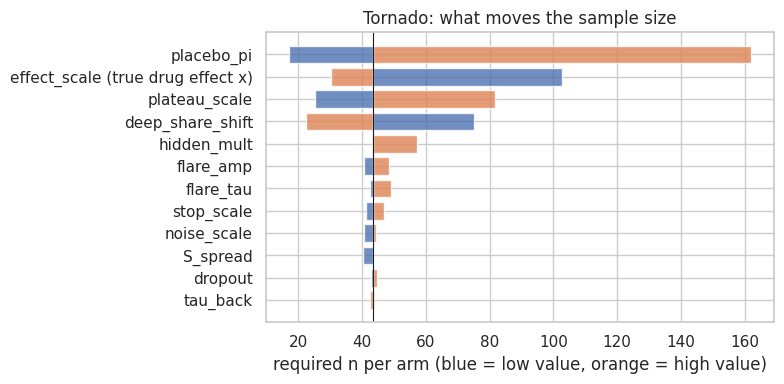

In [72]:
# sensitivity tornado
base_n, base_effect = n_for(PARAMS)

rows = []
for name, (low, high) in RANGES.items():
    n_low, _ = n_for(with_(PARAMS, **{name: low}))
    n_high, _ = n_for(with_(PARAMS, **{name: high}))
    rows.append(dict(parameter=name, low=low, high=high, n_at_low=n_low, n_at_high=n_high, swing=abs(n_high - n_low)))

# The true drug effect is varied through the design, not through the parameters
n_low, _ = n_for(PARAMS, effect_scale=0.7)
n_high, _ = n_for(PARAMS, effect_scale=1.3)
rows.append(dict(parameter="effect_scale (true drug effect x)", low=0.7, high=1.3,
                 n_at_low=n_low, n_at_high=n_high, swing=abs(n_high - n_low)))

TOR = pd.DataFrame(rows).sort_values("swing", ascending=False).reset_index(drop=True)
print(f"base case n per arm = {base_n:.0f}")
print(TOR.round(2).to_string(index=False))

# ---------- Tornado plot ----------
fig, ax = plt.subplots(figsize=(8, 4))
plot_rows = TOR.iloc[::-1].reset_index(drop=True)                 # biggest swing at the top
for i, row in plot_rows.iterrows():
    ax.barh(i, row.n_at_high - base_n, left=base_n, color="C1", alpha=.8)
    ax.barh(i, row.n_at_low - base_n, left=base_n, color="C0", alpha=.8)
ax.set_yticks(range(len(plot_rows)))
ax.set_yticklabels(plot_rows.parameter)
ax.axvline(base_n, color="k", lw=.8)
ax.set(xlabel="required n per arm (blue = low value, orange = high value)", title="Tornado: what moves the sample size")
plt.tight_layout()

draws with n > 1000 per arm (trial not feasible): 3%
required n per arm across all assumptions at once (5/25/50/75/95%): {0.05: 15.0, 0.25: 24.0, 0.5: 36.0, 0.75: 87.0, 0.95: 247.0}
rank correlation with n (largest drivers): {'placebo_pi': 0.69, 'deep_share_shift': -0.41, 'plateau_scale': 0.39, 'effect_scale': -0.31, 'hidden_mult': 0.23, 'noise_scale': -0.17}
PASS | T8 sensitivity | the base case lies inside the 25-75% band of the global range | base 43; band 24-87
PASS | T8 sensitivity | the true drug effect and the placebo response are among the top drivers (the two things the data cannot pin down) | ['placebo_pi', 'deep_share_shift', 'plateau_scale', 'effect_scale']


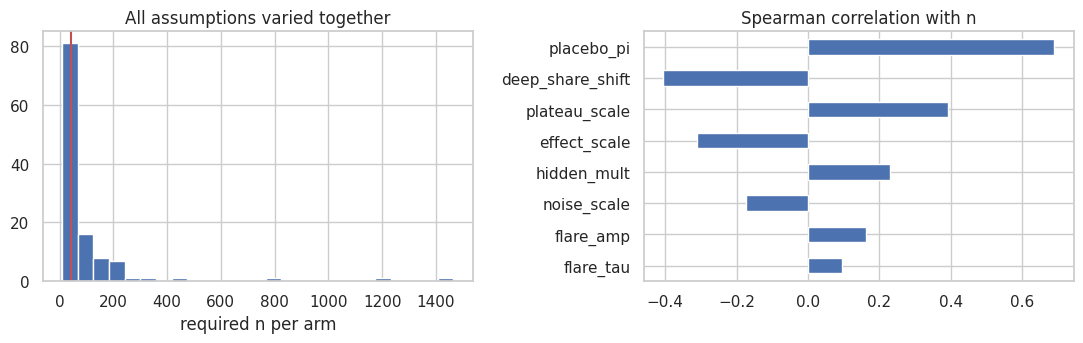

In [73]:
# all assumptions varied together (latin hypercube)
rng_lhs = np.random.default_rng(5)
names = list(RANGES) + ["effect_scale"]
bounds = np.array([RANGES[k] for k in RANGES] + [(0.7, 1.3)])
n_draws = 120

# Latin hypercube: each parameter's range is cut into 120 slices, one draw per slice, in shuffled order
slice_positions = np.column_stack([(rng_lhs.permutation(n_draws) + rng_lhs.random(n_draws)) / n_draws
                                   for _ in names])
draws = bounds[:, 0] + slice_positions * (bounds[:, 1] - bounds[:, 0])          # (120, n_params)

required_n = []
for i in range(n_draws):
    changes = {name: draws[i, j] for j, name in enumerate(RANGES)}              # all parameters but the effect
    effect_scale = draws[i, -1]
    n, _ = n_for(with_(PARAMS, **changes), effect_scale, n_big=1500, seed=300 + i)
    required_n.append(n)

LHS = pd.DataFrame(draws, columns=names).assign(n_per_arm=required_n)
LHS = LHS[np.isfinite(LHS.n_per_arm) & (LHS.n_per_arm > 0) & (LHS.n_per_arm < 5000)]

print(f"draws with n > 1000 per arm (trial not feasible): {(np.array(required_n) > 1000).mean():.0%}")
q = LHS.n_per_arm.quantile([.05, .25, .5, .75, .95])
print("required n per arm across all assumptions at once (5/25/50/75/95%):", q.round(0).to_dict())

# Which assumptions move n the most? (rank correlation, sign shows direction)
rank = LHS.corr(method="spearman")["n_per_arm"].drop("n_per_arm").sort_values(key=abs, ascending=False)
print("rank correlation with n (largest drivers):", rank.round(2).head(6).to_dict())

fig, (ax_hist, ax_rank) = plt.subplots(1, 2, figsize=(11, 3.6))
ax_hist.hist(LHS.n_per_arm, bins=25)
ax_hist.axvline(base_n, color="r")
ax_hist.set(xlabel="required n per arm", title="All assumptions varied together")
rank.head(8).iloc[::-1].plot.barh(ax=ax_rank, title="Spearman correlation with n")
plt.tight_layout()

check("T8 sensitivity", "the base case lies inside the 25-75% band of the global range",
      q[.25] <= base_n <= q[.75] * 1.15, f"base {base_n:.0f}; band {q[.25]:.0f}-{q[.75]:.0f}", warn=True)
top_drivers = list(rank.head(4).index)
check("T8 sensitivity",
      "the true drug effect and the placebo response are among the top drivers (the two things the data cannot pin down)",
      bool(set(top_drivers) & {"effect_scale", "placebo_pi"}), top_drivers)

# 9 - ledger and limitation

In [74]:
L = pd.DataFrame(LEDGER); print(L.status.value_counts().to_dict()); L

{'PASS': 30, 'WARN': 2}


,step,check,status,detail
0,T0 data,there is NO untreated randomised arm in the da...,PASS,placebo is a scenario parameter with a range
1,T2 noise,same-day nugget and the extrapolated 1-14 day ...,PASS,2.08 vs 2.23
2,T2 noise,noise variance grows with the level (n1 > 0),PASS,"n0 = 2.02, n1 = 0.004"
3,T3 flares,flare excess is positive at onset and gone by ...,PASS,"first week 3.89, last weeks -0.14"
4,T3 flares,decay time constant is between 5 and 40 days,PASS,tau = 15.4 d
5,T3 visits,sites differ in how often they score beyond ch...,PASS,SD 0.175
6,T4 treatment,the three response types are ordered and the d...,PASS,shares [0.154 0.302 0.544]
7,T4 treatment,response arrives in months 1-4 (half-response ...,PASS,"{np.str_('deep'): 2.24, np.str_('partial'): 2...."
8,T4 treatment,after stopping the level is back to >= 90% of ...,PASS,1.13
9,T4 treatment,the three response types are ordered and the d...,PASS,shares [0.154 0.302 0.544]


**Limits that simulation can not removes**
1. **Placebo response is an assumption** (no placebo group): a scenario parameter with range 0-18%. Regression to the mean and natural flare decay are in the model and tested (V2); *true* placebo is not.
2. **Hidden flares** (flares without an antibiotic mark) are not identifiable from these data; they are the `hidden_mult` parameter.
3. **Dense scheduled scores are missing**, so noise, flare shape and drift come from irregular clinic visits. A pilot with scores every 2-4 weeks for 24 weeks would replace three assumptions at once.
4. **Estimator bias from hidden flares:** when the simulator contains hidden flares the flare-decay estimator (which reads only marked flares) recovers a time constant that is too long (V1), so the real-data value of 15 days is probably a slight overstatement of how slowly a flare fades. The visit-frequency check stays a WARN: the simulator produces about 4 visits per patient-year against 7 in the real data; scores, not visit counts, are what the trial design uses.
5. **On-drug curves** carry start-at-flare and survivorship biases; the simulator reproduces them (V1 shows what the estimators recover) but the plateau of the minimal responders and the return time constant after stopping are the weakest estimates.
6. **Response types** are a mixture fitted to the log ratio; they are descriptive classes, not proven biology.
7. **What to replace first with trial data:** placebo response, drop-out, and scheduled-visit noise.